# DogPoseCV: 사전학습 ViT와 LoRA를 이용한 강아지 자세 분류

**문제:** 강아지 사진을 `standing`(서 있음), `sitting`(앉음), `lying down`(누움)으로 분류한다.
견종은 메타정보이며 자세 정답이 아니다. `undefined`는 자세가 불명확해 기본 학습에서 제외한다.

**실험:** 같은 ViT·초기 classifier·분할·전처리로 head만 학습한 Baseline과 query/value LoRA+head를 비교한다.
기존 `skeleton.ipynb`의 함수명과 입력·반환 계약을 유지하되, 데이터 누출 방지를 위해 그룹 단위 70/15/15 분할을 사용한다.
원본 스켈레톤·Beans 예시·README는 수정하지 않는다. 예시의 점수를 이번 결과로 사용하지 않는다.

**출처:** [DogPoseCV 데이터셋 카드](https://huggingface.co/datasets/stockeh/dog-pose-cv),
Stock, Jason and Tom Cavey (2021), *Who's a Good Boy? Reinforcing Canine Behavior in Real-Time using Machine Learning*,
[arXiv:2101.02380](https://arxiv.org/abs/2101.02380).
데이터셋 카드는 Stanford Dogs 사진에 자세를 재라벨링했다고 설명하며, Hub 메타데이터의 라이선스 표기는 Apache-2.0이다.
이 표기만으로 원본 사진의 모든 권리가 허가되었다고 단정하지 않는다.
[원 사진 출처](http://vision.stanford.edu/aditya86/ImageNetDogs/)의 사용 조건도 확인해야 하며 원본 아카이브를 재배포하지 않는다.

**실행 상태:** 아래 출력이 실제 실행 여부의 근거다. `audit`는 전체 데이터 감사와 모델 점검만 실행한다.
`train`은 전체 학습·최종 Test·예측 비교·adapter 복원까지 실행한다.
CPU에서 전체 학습은 오래 걸리므로 GPU가 없으면 기본값은 `audit`다. 미실행 점수는 생성하지 않는다.

## 1. 환경과 실행 설정

VS Code는 기존 `.venv` 커널을 사용한다. Colab은 GPU 런타임을 선택한다.
다음 설치 셀은 **Colab에서 누락된 직접 의존성만** 설치한다. 기존 GPU용 torch/torchvision을 고정해 교체를 막는다.
이미 설치된 버전은 다음 셀에 기록한다. import/API 오류가 생기면 그 오류를 해결한 후 실행하고, 자동 전체 업그레이드는 하지 않는다.

In [20]:
import sys, importlib.util, importlib.metadata, subprocess, tempfile
from pathlib import Path
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
required = {
    "torch": "torch==2.9.1", "torchvision": "torchvision==0.24.1",
    "transformers": "transformers==4.57.3", "peft": "peft==0.18.0",
    "accelerate": "accelerate==1.12.0", "datasets": "datasets==4.4.1",
    "sklearn": "scikit-learn==1.7.2", "pandas": "pandas==2.3.3",
    "numpy": "numpy==2.2.6", "matplotlib": "matplotlib==3.10.7",
    "seaborn": "seaborn==0.13.2", "PIL": "Pillow==12.0.0", "imagehash": "ImageHash==4.3.2",
}
missing = [spec for module, spec in required.items() if importlib.util.find_spec(module) is None]
if missing and IN_COLAB:
    with tempfile.TemporaryDirectory() as tmp:
        constraint = Path(tmp) / "torch-constraints.txt"
        constraint.write_text("\n".join(f"{p}=={importlib.metadata.version(p)}"
            for p in ("torch", "torchvision") if importlib.util.find_spec(p)), encoding="utf-8")
        subprocess.run([sys.executable, "-m", "pip", "install", "-c", str(constraint), *missing], check=True)
elif missing:
    raise RuntimeError(f".venv 커널과 requirements.txt 확인 필요. 누락: {missing}")
else:
    print("필수 패키지 존재: 재설치하지 않음")

필수 패키지 존재: 재설치하지 않음


In [21]:
%pip uninstall -y torchao

In [22]:
import os, json, csv, hashlib, tarfile, shutil, re, time, warnings, gc
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import PurePosixPath
from itertools import combinations
import numpy as np
import pandas as pd
import torch, torchvision, transformers, peft, accelerate
import matplotlib.pyplot as plt
import seaborn as sns
import imagehash
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from datasets import Dataset, DatasetDict, ClassLabel
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (AutoImageProcessor, AutoModelForImageClassification, Trainer,
    TrainingArguments, EarlyStoppingCallback, default_data_collator, pipeline, set_seed)
from peft import LoraConfig, PeftModel, get_peft_model

print("Python:", sys.version, "\n실행 파일:", sys.executable, "\nColab:", IN_COLAB)
versions = {name: importlib.metadata.version(name) for name in [
    "torch", "torchvision", "transformers", "peft", "accelerate", "datasets", "scikit-learn",
    "pandas", "numpy", "matplotlib", "seaborn", "Pillow", "ImageHash"]}
display(pd.Series(versions, name="실제 설치 버전").to_frame())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("장치:", DEVICE, "PyTorch CUDA build:", torch.version.cuda)
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(props.name, f"총 GPU 메모리 {props.total_memory / 2**30:.2f} GiB")
else:
    torch.set_num_threads(min(8, os.cpu_count() or 1))
    print("GPU 없음: 전체 학습 대신 기본 audit 모드. Colab GPU에서 RUN_MODE='train'으로 실행하세요.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 
실행 파일: /usr/bin/python3 
Colab: True


,실제 설치 버전
torch,2.14.1+cu130
torchvision,0.29.1+cu130
transformers,5.22.1
peft,0.21.2
accelerate,1.15.0
datasets,4.8.5
scikit-learn,1.6.1
pandas,2.2.3
numpy,2.4.6
matplotlib,3.10.0


장치: cuda PyTorch CUDA build: 13.0
Tesla T4 총 GPU 메모리 14.56 GiB


In [23]:
# 경로와 실험 설정은 이 셀에서만 변경한다.
TASK = "Vision"
DATASET_ID = "stockeh/dog-pose-cv"
PROJECT_DIR = Path("/content") if IN_COLAB else Path.cwd()
RUN_MODE = "train"  # 먼저 감사. 통과한 뒤 Colab GPU에서만 수동으로 train 선택
DRIVE_MOUNT_PATH = Path("/content/drive")
DRIVE_DATA_FOLDER = "DogPoseCV"  # 대소문자 유지. Colab 경로는 이 설정에서만 정의
REMOUNT_DRIVE_ON_MISSING = True
def runtime_paths(in_colab, project_dir, mount_path, folder):
    archive_dir = mount_path / "MyDrive" / folder if in_colab else project_dir / "data" / "raw"
    return {"archive_dir": archive_dir,
            "images": archive_dir / "images.tar.gz" if in_colab else None,
            "labels": archive_dir / "labels.tar.gz" if in_colab else None,
            "extract_dir": project_dir / "data" / "processed",
            "output_dir": archive_dir / "outputs" if in_colab else project_dir / "outputs"}
_paths = runtime_paths(IN_COLAB, PROJECT_DIR, DRIVE_MOUNT_PATH, DRIVE_DATA_FOLDER)
DATA_ARCHIVE_DIR = _paths["archive_dir"]
IMAGE_ARCHIVE_PATH = _paths["images"]  # 로컬에서 다른 위치를 쓸 때만 이 셀에서 지정
LABEL_ARCHIVE_PATH = _paths["labels"]
EXTRACT_DIR = _paths["extract_dir"]
OUTPUT_DIR = _paths["output_dir"]
MODEL_ID = "google/vit-base-patch16-224-in21k"
MODEL_REVISION = "main"  # 로드 후 실제 commit SHA를 기록하고 후속 모델도 그 revision으로 로드
SEED = 42
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 2
EPOCHS = 3
LEARNING_RATE = 5e-4
OPTIMIZER = "adamw_torch"
WEIGHT_DECAY = 0.01
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.1
SPLIT_RATIOS = (0.70, 0.15, 0.15)
CHECK_PRETRAINED_MODEL = True  # audit에서도 다운로드/실제 Train 샘플 forward 점검
ALLOW_CPU_FULL_TRAINING = False
UNLABELED_POLICY = "exclude_unverified"  # 보류는 보존·제외. 실제 사용 데이터의 미확인 라벨은 허용하지 않음
USER_IMAGE_PATH = None  # 학습 완료 후 사용자 이미지 경로 지정
LABELS = ["standing", "sitting", "lying down"]
id2label = dict(enumerate(LABELS))
label2id = {name: i for i, name in id2label.items()}
assert RUN_MODE in {"audit", "train"}
assert UNLABELED_POLICY == "exclude_unverified", "미확인 라벨은 학습·평가에서 제외해야 합니다."
assert np.isclose(sum(SPLIT_RATIOS), 1)
if RUN_MODE == "train" and DEVICE == "cpu" and not ALLOW_CPU_FULL_TRAINING:
    raise RuntimeError("전체 CPU 학습은 기본 차단. Colab GPU를 사용하거나 ALLOW_CPU_FULL_TRAINING=True를 명시하세요.")
set_seed(SEED)
def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("RUN_MODE:", RUN_MODE, "\nlabel2id:", label2id)

RUN_MODE: train 
label2id: {'standing': 0, 'sitting': 1, 'lying down': 2}


### Colab Drive 마운트와 파일 존재 확인 (필수 순서)

Colab에서는 다음 셀이 `/content/drive`를 마운트하고 `MyDrive/DogPoseCV/`의 두 아카이브를 직접 확인한다.
없으면 기대 경로와 실제 파일 목록을 출력하고 한 번 재마운트해 다시 확인한다. 별도 수동 확인 셀은 필요 없다.
Drive는 영구 저장소이고 `/content`는 런타임 종료 때 삭제되는 임시 저장소다.
압축 해제는 `/content/data/processed`, 출력은 `/content/drive/MyDrive/DogPoseCV/outputs`에 저장한다.
약 780 MB 사진 아카이브의 다운로드·업로드·압축 해제에는 시간이 걸린다.

In [24]:
def check_archive_paths(folder, archive_paths):
    exists = [Path(path).is_file() for path in archive_paths]
    try:
        listing = sorted(path.name + ("/" if path.is_dir() else "") for path in Path(folder).iterdir())
    except OSError as exc:
        listing = [f"목록 읽기 실패: {type(exc).__name__}: {exc}"]
    for path, found in zip(archive_paths, exists): print("아카이브 기대 경로:", path, "존재:", found)
    print("실제 Drive 데이터 폴더:", folder, "파일 목록:", listing)
    if not all(exists):
        parent = Path(folder).parent
        parent_listing = sorted(p.name for p in parent.iterdir()) if parent.is_dir() else []
        raise FileNotFoundError(f"Drive 아카이브 확인 실패. 기대 경로: {[str(p) for p in archive_paths]}; "
                                f"실제 {folder} 목록: {listing}; 상위 폴더 {parent} 목록: {parent_listing}. "
                                "DogPoseCV 대소문자와 연결한 Google 계정을 확인하세요.")
    return exists

if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount(str(DRIVE_MOUNT_PATH))
        try:
            check_archive_paths(DATA_ARCHIVE_DIR, [IMAGE_ARCHIVE_PATH, LABEL_ARCHIVE_PATH])
        except FileNotFoundError:
            if not REMOUNT_DRIVE_ON_MISSING: raise
            print("파일이 보이지 않아 Drive를 한 번 재마운트하고 다시 확인합니다.")
            drive.mount(str(DRIVE_MOUNT_PATH), force_remount=True)
            check_archive_paths(DATA_ARCHIVE_DIR, [IMAGE_ARCHIVE_PATH, LABEL_ARCHIVE_PATH])
    except Exception as exc:
        print("Drive 마운트/파일 확인 실패:", type(exc).__name__, str(exc))
        print("기대한 두 파일:", IMAGE_ARCHIVE_PATH, LABEL_ARCHIVE_PATH)
        raise
else:
    print("로컬 VS Code: Drive 마운트를 생략하고 기존 루트/data/raw 아카이브를 검색합니다.")
for sub in ["baseline", "lora_adapter", "evaluation", "figures", "predictions"]:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
print("아카이브 검색 경로:", DATA_ARCHIVE_DIR, "\n출력 경로:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
아카이브 기대 경로: /content/drive/MyDrive/DogPoseCV/images.tar.gz 존재: True
아카이브 기대 경로: /content/drive/MyDrive/DogPoseCV/labels.tar.gz 존재: True
실제 Drive 데이터 폴더: /content/drive/MyDrive/DogPoseCV 파일 목록: ['images.tar.gz', 'labels.tar.gz', 'outputs/']
아카이브 검색 경로: /content/drive/MyDrive/DogPoseCV 
출력 경로: /content/drive/MyDrive/DogPoseCV/outputs


## 2. 아카이브 발견·검증·안전한 압축 해제

명시적 경로 → `data/raw` → 프로젝트 루트 → 프로젝트 전체 검색 순서로 찾는다.
기존 파일은 이동·복사·재다운로드하지 않는다. 없을 때만 공식 Hugging Face URL에서 `.part`로 받고
gzip/tar 전체 목록을 검증한 뒤 이름을 변경한다. 오류·HTML·0바이트는 실패로 처리한다.
절대경로, `..`, Windows 드라이브, 링크, 특수파일 및 중복 정규화 경로는 거부한다.
알려진 macOS 메타데이터만 제외한다. 추출 완료 표식은 아카이브 fingerprint와 파일별 크기를 검증한다.

In [25]:
import urllib.request
ARCHIVE_URLS = {name: f"https://huggingface.co/datasets/{DATASET_ID}/resolve/main/data/{name}?download=true"
                for name in ("images.tar.gz", "labels.tar.gz")}
def is_metadata(name):
    return any(p == "__MACOSX" or p == ".DS_Store" or p.startswith("._")
               for p in PurePosixPath(name.replace("\\", "/")).parts)

def checked_target(root, name):
    p = PurePosixPath(name.replace("\\", "/"))
    if p.is_absolute() or ".." in p.parts or any(":" in part for part in p.parts):
        raise ValueError(f"안전하지 않은 tar 경로: {name}")
    target = (root / Path(*p.parts)).resolve()
    if not target.is_relative_to(root.resolve()):
        raise ValueError(f"추출 경로 이탈: {name}")
    return target

def inspect_archive(path):
    if path.stat().st_size == 0:
        raise ValueError(f"0바이트 아카이브: {path}")
    with path.open("rb") as f:
        if f.read(2) != b"\x1f\x8b":
            raise ValueError(f"gzip magic 불일치 (HTML 오류 가능): {path}")
    with tarfile.open(path, "r:gz") as archive:
        members = archive.getmembers()  # gzip 스트림 끝까지 읽어 손상도 검사
        seen = set()
        for member in members:
            target = checked_target(EXTRACT_DIR, member.name)
            if not (member.isfile() or member.isdir()):
                raise ValueError(f"링크/특수파일 거부: {member.name}")
            if member.isfile():
                if target in seen:
                    raise ValueError(f"중복 tar 경로: {member.name}")
                seen.add(target)
        if not any(m.isfile() and not is_metadata(m.name) for m in members):
            raise ValueError(f"실제 데이터 파일이 없는 tar: {path}")
    return members

def find_archive(name, explicit):
    if explicit is not None:
        path = Path(explicit).expanduser().resolve()
        if not path.is_file():
            if IN_COLAB:
                check_archive_paths(DATA_ARCHIVE_DIR, [IMAGE_ARCHIVE_PATH, LABEL_ARCHIVE_PATH])
            raise FileNotFoundError(f"명시한 파일 없음: {path}")
        return path, "지정 경로"
    for path in [DATA_ARCHIVE_DIR / name, PROJECT_DIR / name]:
        if path.is_file(): return path.resolve(), "기존 파일"
    found = sorted(p for p in PROJECT_DIR.rglob(name) if ".venv" not in p.parts)
    if len(found) > 1:
        raise ValueError(f"아카이브가 여러 개임. 경로를 지정하세요: {found}")
    if found: return found[0].resolve(), "프로젝트 검색"
    DATA_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
    path = DATA_ARCHIVE_DIR / name
    part = path.with_name(name + ".part")
    print(f"{name} 없음: Colab은 Drive 경로 지정 또는 파일 패널 업로드도 가능. 공식 다운로드 시도")
    try:
        with urllib.request.urlopen(ARCHIVE_URLS[name], timeout=60) as response, part.open("wb") as dest:
            if "text/html" in response.headers.get("Content-Type", ""):
                raise ValueError("서버가 HTML을 반환함")
            expected = response.headers.get("Content-Length")
            shutil.copyfileobj(response, dest, length=1024 * 1024)
        if expected and part.stat().st_size != int(expected):
            raise IOError(f"불완전 다운로드: {part.stat().st_size}/{expected} bytes")
        inspect_archive(part)
        part.replace(path)
    except Exception as exc:
        raise RuntimeError(f"{name} 다운로드 실패 ({ARCHIVE_URLS[name]}): {type(exc).__name__}: {exc}") from exc
    return path.resolve(), "공식 다운로드"

archive_info = {}
for name, explicit in [("images.tar.gz", IMAGE_ARCHIVE_PATH), ("labels.tar.gz", LABEL_ARCHIVE_PATH)]:
    path, origin = find_archive(name, explicit)
    members = inspect_archive(path)
    info = {"path": str(path), "source": origin, "bytes": path.stat().st_size,
            "mtime_ns": path.stat().st_mtime_ns, "members": len(members),
            "regular_files": sum(m.isfile() for m in members),
            "metadata_files_excluded": sum(m.isfile() and is_metadata(m.name) for m in members)}
    real = [m for m in members if m.isfile() and not is_metadata(m.name)]
    info["data_files"] = len(real)
    print(name, json.dumps(info, ensure_ascii=False))
    display(pd.DataFrame([{"name": m.name, "bytes": m.size, "metadata": is_metadata(m.name)} for m in members[:14]]))
    marker = EXTRACT_DIR / f".{name}.complete.json"
    expected_files = {m.name: m.size for m in real}
    stamp = {"archive": info, "files": expected_files}
    complete = marker.exists() and json.loads(marker.read_text(encoding="utf-8")) == stamp
    complete = complete and all(checked_target(EXTRACT_DIR, n).is_file()
             and checked_target(EXTRACT_DIR, n).stat().st_size == size for n, size in expected_files.items())
    if complete:
        print("완료 표식·파일 크기 검증 통과: 재추출 생략")
    else:
        print("안전 추출 시작:", len(real), "files", flush=True)
        with tarfile.open(path, "r:gz") as archive:
            for index, member in enumerate(real):
                target = checked_target(EXTRACT_DIR, member.name)
                target.parent.mkdir(parents=True, exist_ok=True)
                # 재시도 시 같은 크기의 이미 추출된 파일은 유지한다.
                if target.is_file() and target.stat().st_size == member.size: continue
                temp = target.with_name(target.name + ".part")
                with archive.extractfile(member) as src, temp.open("wb") as dst:
                    shutil.copyfileobj(src, dst)
                if temp.stat().st_size != member.size:
                    raise IOError(f"추출 크기 불일치: {member.name}")
                temp.replace(target)
        write_json(marker, stamp)
        print("추출 완료")
    archive_info[name] = info
write_json(EXTRACT_DIR / "archive_inventory.json", archive_info)

images.tar.gz {"path": "/content/drive/MyDrive/DogPoseCV/images.tar.gz", "source": "지정 경로", "bytes": 779709927, "mtime_ns": 1795622588000000000, "members": 41708, "regular_files": 41586, "metadata_files_excluded": 20856, "data_files": 20730}


,name,bytes,metadata
0,._images,312,True
1,images,0,False
2,images/._n02097658-silky_terrier,212,True
3,images/n02097658-silky_terrier,0,False
4,images/._n02092002-Scottish_deerhound,212,True
5,images/n02092002-Scottish_deerhound,0,False
6,images/._n02099849-Chesapeake_Bay_retriever,212,True
7,images/n02099849-Chesapeake_Bay_retriever,0,False
8,images/._n02091244-Ibizan_hound,212,True
9,images/n02091244-Ibizan_hound,0,False


완료 표식·파일 크기 검증 통과: 재추출 생략
labels.tar.gz {"path": "/content/drive/MyDrive/DogPoseCV/labels.tar.gz", "source": "지정 경로", "bytes": 104662, "mtime_ns": 1795622496000000000, "members": 242, "regular_files": 241, "metadata_files_excluded": 122, "data_files": 119}


,name,bytes,metadata
0,._labels,212,True
1,labels,0,False
2,labels/._n02085936-Maltese_dog.csv,312,True
3,labels/n02085936-Maltese_dog.csv,6919,False
4,labels/._n02093256-Staffordshire_bullterrier.csv,312,True
5,labels/n02093256-Staffordshire_bullterrier.csv,4301,False
6,labels/._n02106550-Rottweiler.csv,312,True
7,labels/n02106550-Rottweiler.csv,4192,False
8,labels/._n02099601-golden_retriever.csv,312,True
9,labels/n02099601-golden_retriever.csv,4090,False


완료 표식·파일 크기 검증 통과: 재추출 생략


## 3. 실제 CSV 구조와 이미지 매칭

CSV에서 실제 `id,label` 열과 추가 split 열을 검사한다. CSV 파일의 stem(견종 폴더명)과
정규화된 이미지 stem을 **함께** 키로 사용한다. 경로 구분자·확장자·대소문자를 정리하며
중복 키는 목록으로 유지한다. 이미지 파일명만으로 다른 견종의 데이터를 덮어쓰지 않는다.
같은 키에 라벨 행이 여러 개 있으면 모호한 매칭으로 표시하고 기본 학습에서 제외한다.
`lying`은 의미가 같은 `lying down`으로만 변환하며 알 수 없는 값은 `unknown`으로 기록한다.

In [26]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
image_files = sorted(p for p in EXTRACT_DIR.rglob("*") if p.is_file()
    and p.suffix.lower() in IMAGE_SUFFIXES and not is_metadata(p.relative_to(EXTRACT_DIR).as_posix()))
csv_files = sorted(p for p in EXTRACT_DIR.rglob("*.csv") if "labels" in p.relative_to(EXTRACT_DIR).parts
                   and not is_metadata(p.name))
if not image_files or not csv_files:
    raise RuntimeError("실제 이미지/견종별 라벨 CSV 없음. 압축 구조와 경로 확인 필요")
def normalized_id(value):
    return PurePosixPath(str(value).strip().replace("\\", "/")).stem.casefold()
def normalize_label(value):
    label = re.sub(r"[\s_-]+", " ", str(value).strip().casefold())
    return {"lying": "lying down", "lying down": "lying down", "standing": "standing",
            "sitting": "sitting", "undefined": "undefined"}.get(label, "unknown")
label_rows, csv_summary = [], []
for path in csv_files:
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    print_sample = len(csv_summary) == 0
    if not {"id", "label"} <= set(frame.columns):
        raise ValueError(f"CSV 열 불일치: {path}, 실제 열={list(frame.columns)}")
    split_cols = [c for c in frame.columns if c.casefold() in {"split", "subset", "partition"}]
    if len(split_cols) > 1: raise ValueError(f"여러 split 열을 직접 확인하세요: {path}")
    if print_sample:
        print("실제 CSV:", path, "열:", list(frame.columns)); display(frame.head(8))
    csv_summary.append({"source_csv": str(path.relative_to(EXTRACT_DIR)), "rows": len(frame),
                        "columns": list(frame.columns), "missing_id": int(frame.id.eq("").sum()),
                        "missing_label": int(frame.label.eq("").sum())})
    for row in frame.to_dict("records"):
        label_rows.append({"source_csv": str(path.relative_to(EXTRACT_DIR)), "id": row["id"],
            "key": (path.stem.casefold(), normalized_id(row["id"])), "label_raw": row["label"],
            "label_normalized": normalize_label(row["label"]),
            "official_split": row[split_cols[0]].strip().casefold() if split_cols else ""})
label_index = defaultdict(list)
for i, row in enumerate(label_rows): label_index[row["key"]].append((i, row))
image_keys = [(p.parent.name.casefold(), normalized_id(p.name)) for p in image_files]
image_key_counts = Counter(image_keys)
records, used_label_rows = [], set()
for path, key in zip(image_files, image_keys):
    matches = label_index.get(key, [])
    used_label_rows.update(i for i, _ in matches)
    status = "matched" if len(matches) == 1 and image_key_counts[key] == 1 else (
        "unmatched_image" if not matches else "ambiguous_key")
    row = matches[0][1] if status == "matched" else {}
    records.append({"image_path": path.relative_to(EXTRACT_DIR).as_posix(),
        "source_csv": row.get("source_csv", ""), "id": path.name,
        "label_raw": row.get("label_raw", ""), "label_normalized": row.get("label_normalized", "unknown"),
        "breed_folder": path.parent.name, "match_status": status,
        "official_split": row.get("official_split", "")})
manifest = pd.DataFrame(records)
unmatched_labels = [row for i, row in enumerate(label_rows) if i not in used_label_rows]
pd.DataFrame(unmatched_labels).to_csv(EXTRACT_DIR / "unmatched_labels.csv", index=False)
pd.DataFrame(csv_summary).to_csv(EXTRACT_DIR / "csv_inventory.csv", index=False)
manifest.groupby("breed_folder").size().rename("images").to_csv(EXTRACT_DIR / "breed_image_counts.csv")
print("이미지 확장자:", dict(Counter(p.suffix.lower() for p in image_files)))
print("이미지/CSV/라벨행:", len(image_files), len(csv_files), len(label_rows))
print("매칭 상태:", manifest.match_status.value_counts().to_dict(), "미매칭 라벨행:", len(unmatched_labels))
print("중복 라벨 키(추가 행):", sum(len(v)-1 for v in label_index.values()))
print("여러 폴더의 동일 이미지 stem 수:", int(pd.Series([normalized_id(p.name) for p in image_files]).value_counts().gt(1).sum()))
display(manifest.head())

실제 CSV: /content/data/processed/labels/n02085620-Chihuahua.csv 열: ['id', 'label']


,id,label
0,n02085620_4700.jpg,undefined
1,n02085620_712.jpg,lying
2,n02085620_9351.jpg,sitting
3,n02085620_2204.jpg,lying
4,n02085620_1916.jpg,undefined
5,n02085620_2614.jpg,sitting
6,n02085620_1321.jpg,standing
7,n02085620_1862.jpg,sitting


이미지 확장자: {'.jpg': 20730}
이미지/CSV/라벨행: 20730 119 20423
매칭 상태: {'matched': 20423, 'unmatched_image': 307} 미매칭 라벨행: 0
중복 라벨 키(추가 행): 0
여러 폴더의 동일 이미지 stem 수: 139


,image_path,source_csv,id,label_raw,label_normalized,breed_folder,match_status,official_split
0,images/n02085620-Chihuahua/n02085620_10074.jpg,labels/n02085620-Chihuahua.csv,n02085620_10074.jpg,standing,standing,n02085620-Chihuahua,matched,
1,images/n02085620-Chihuahua/n02085620_10131.jpg,labels/n02085620-Chihuahua.csv,n02085620_10131.jpg,standing,standing,n02085620-Chihuahua,matched,
2,images/n02085620-Chihuahua/n02085620_10621.jpg,labels/n02085620-Chihuahua.csv,n02085620_10621.jpg,undefined,undefined,n02085620-Chihuahua,matched,
3,images/n02085620-Chihuahua/n02085620_1073.jpg,labels/n02085620-Chihuahua.csv,n02085620_1073.jpg,undefined,undefined,n02085620-Chihuahua,matched,
4,images/n02085620-Chihuahua/n02085620_10976.jpg,labels/n02085620-Chihuahua.csv,n02085620_10976.jpg,sitting,sitting,n02085620-Chihuahua,matched,


## 4. 전체 이미지 무결성·중복 감사와 매니페스트

모든 파일을 SHA256으로 해시하고 Pillow로 디코딩한다. EXIF 회전 후 RGB로 변환해 크기·원래 모드·채널을 기록한다.
파일 SHA와 디코딩 RGB 픽셀 해시가 같은 이미지는 동일 그룹이다. pHash가 같은 후보도 기록하고,
종횡비 차이 1% 이하 및 32×32 RGB 평균 절대차 2/255 이하인 후보만 보수적으로 같은 그룹으로 묶는다.
이는 모든 크롭·시점 변화·동일 개체를 발견한다는 보장이 없다.
중복은 삭제하지 않고 같은 split으로 묶는다. 그룹 내 자세 라벨이 충돌하면 전체 그룹을 학습에서 제외한다.
매칭 실패·unknown·손상·undefined는 각각 사유를 남긴다.

In [27]:
audit_start = time.time()
inspection, previews = [], {}
verified_cache = globals().get("_verified_inspection_cache")
for i, row in enumerate(manifest.itertuples(index=False)):
    path = EXTRACT_DIR / row.image_path
    if verified_cache is not None:
        # 재검사 도구가 모든 원본 SHA256을 재확인한 경우에만 이전 디코딩 결과를 재사용한다.
        cached = verified_cache[row.image_path]
        inspection.append({field: cached[field] for field in ["sha256", "pixel_sha256", "phash", "width", "height",
            "source_mode", "source_channels", "image_status", "image_error"]})
        continue
    item = {"sha256": "", "pixel_sha256": "", "phash": "", "width": 0, "height": 0,
            "source_mode": "", "source_channels": 0, "image_status": "ok", "image_error": ""}
    try:
        item["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
        with Image.open(path) as source:
            source.verify()
        with Image.open(path) as source:
            item["source_mode"], item["source_channels"] = source.mode, len(source.getbands())
            rgb = ImageOps.exif_transpose(source).convert("RGB")
            rgb.load()
            item["width"], item["height"] = rgb.size
            if min(rgb.size) <= 0: raise ValueError("0 크기 이미지")
            item["pixel_sha256"] = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
            item["phash"] = str(imagehash.phash(rgb))
            previews[i] = np.asarray(rgb.resize((32, 32), Image.Resampling.LANCZOS), dtype=np.int16)
    except Exception as exc:
        item["image_status"] = "unreadable"
        item["image_error"] = f"{type(exc).__name__}: {exc}"
    inspection.append(item)
    if (i + 1) % 2000 == 0: print(f"검사 {i+1}/{len(manifest)}", flush=True)
manifest = pd.concat([manifest, pd.DataFrame(inspection)], axis=1)
# `images/validation`에는 CSV가 없다. 다른 정답 사진과 byte-identical인지 별도 확인만 한다.
# 라벨은 복사하지 않으며 이 폴더를 공식 split으로 추정하지 않는다.
known_sha = set(manifest.loc[manifest.match_status.eq("matched"), "sha256"])
manifest["unmatched_reason"] = ""
for i, row in manifest.loc[manifest.match_status.ne("matched")].iterrows():
    if row.breed_folder == "validation" and row.sha256 in known_sha:
        reason = "auxiliary_validation_exact_copy_without_csv"
    elif not (EXTRACT_DIR / "labels" / f"{row.breed_folder}.csv").is_file():
        reason = "missing_breed_csv"
    else:
        reason = "id_absent_from_breed_csv"
    manifest.at[i, "unmatched_reason"] = reason
manifest.loc[manifest.match_status.ne("matched")].to_csv(EXTRACT_DIR / "unmatched_images.csv", index=False)
parent = list(range(len(manifest)))
def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b):
    a, b = find_group(a), find_group(b)
    if a != b: parent[max(a, b)] = min(a, b)
for field in ["sha256", "pixel_sha256"]:
    for _, indexes in manifest.loc[manifest[field].ne("")].groupby(field).groups.items():
        indexes = list(indexes)
        for i in indexes[1:]: union(indexes[0], i)
perceptual_pairs = []
for _, indexes in manifest.loc[manifest.phash.ne("")].groupby("phash").groups.items():
    for a, b in combinations(indexes, 2):
        ra, rb = manifest.loc[a], manifest.loc[b]
        for index in [a, b]:
            if index not in previews:
                with Image.open(EXTRACT_DIR / manifest.loc[index, "image_path"]) as source:
                    rgb = ImageOps.exif_transpose(source).convert("RGB")
                    previews[index] = np.asarray(rgb.resize((32,32), Image.Resampling.LANCZOS), dtype=np.int16)
        error = float(np.abs(previews[a] - previews[b]).mean())
        ratio_diff = abs((ra.width / ra.height) / (rb.width / rb.height) - 1)
        confirmed = error <= 2.0 and ratio_diff <= 0.01
        perceptual_pairs.append({"a": ra.image_path, "b": rb.image_path, "rgb_mae": error,
                                 "ratio_difference": ratio_diff, "grouped": confirmed})
        if confirmed: union(a, b)
pd.DataFrame(perceptual_pairs, columns=["a", "b", "rgb_mae", "ratio_difference", "grouped"]).to_csv(
    EXTRACT_DIR / "perceptual_duplicate_candidates.csv", index=False)
manifest["duplicate_group"] = [f"group_{find_group(i):05d}" for i in range(len(manifest))]
label_cardinality = manifest.loc[manifest.match_status.eq("matched")].groupby("duplicate_group").label_normalized.nunique()
conflicting_groups = set(label_cardinality[label_cardinality.gt(1)].index)
manifest["exclusion_reason"] = ""
for i, row in manifest.iterrows():
    reasons = []
    if row.match_status != "matched": reasons.append(row.match_status)
    if row.image_status != "ok": reasons.append(row.image_status)
    if row.label_normalized not in LABELS: reasons.append(row.label_normalized)
    if row.duplicate_group in conflicting_groups: reasons.append("duplicate_label_conflict")
    manifest.at[i, "exclusion_reason"] = ";".join(reasons)
manifest["split"] = np.where(manifest.exclusion_reason.eq(""), "pending", "excluded")
manifest.to_csv(EXTRACT_DIR / "dataset_manifest.csv", index=False)
raw_counts = manifest.loc[manifest.match_status.eq("matched"), "label_raw"].value_counts().to_dict()
normalized_counts = manifest.loc[manifest.match_status.eq("matched"), "label_normalized"].value_counts().to_dict()
expected = {"standing": 4143, "sitting": 3038, "lying down": 7090, "undefined": 6307}
audit = {
    "executed_utc": datetime.now(timezone.utc).isoformat(), "archives": archive_info,
    "python": sys.version, "versions": versions, "image_count": len(manifest), "csv_count": len(csv_files),
    "csv_rows": len(label_rows), "csv_inventory": csv_summary,
    "image_extensions": dict(Counter(p.suffix.lower() for p in image_files)),
    "raw_label_counts": raw_counts, "normalized_label_counts": normalized_counts,
    "expected_reference_only": expected, "difference_from_reference": {k: normalized_counts.get(k, 0)-v for k,v in expected.items()},
    "matched_images": int(manifest.match_status.eq("matched").sum()),
    "unmatched_images": int(manifest.match_status.eq("unmatched_image").sum()),
    "ambiguous_images": int(manifest.match_status.eq("ambiguous_key").sum()), "unmatched_label_rows": len(unmatched_labels),
    "duplicate_label_extra_rows": sum(len(v)-1 for v in label_index.values()),
    "duplicate_image_id_extra_rows": sum(v-1 for v in image_key_counts.values()),
    "repeated_stems_across_folders": int(pd.Series([normalized_id(p.name) for p in image_files]).value_counts().gt(1).sum()),
    "undefined_excluded": int(manifest.label_normalized.eq("undefined").sum()),
    "unknown_labels": int((manifest.label_normalized.eq("unknown") & manifest.match_status.eq("matched")).sum()),
    "unmatched_reasons": manifest.loc[manifest.unmatched_reason.ne("")].unmatched_reason.value_counts().to_dict(),
    "corrupt_images": int(manifest.image_status.ne("ok").sum()),
    "exact_duplicate_extra_files": int(manifest.loc[manifest.sha256.ne("")].sha256.duplicated().sum()),
    "decoded_duplicate_extra_files": int(manifest.loc[manifest.pixel_sha256.ne("")].pixel_sha256.duplicated().sum()),
    "perceptual_candidate_pairs": len(perceptual_pairs), "perceptual_grouped_pairs": int(sum(p["grouped"] for p in perceptual_pairs)),
    "conflicting_duplicate_groups": len(conflicting_groups),
    "excluded_images": int(manifest.split.eq("excluded").sum()), "eligible_images": int(manifest.split.eq("pending").sum()),
    "exclusion_reasons": manifest.loc[manifest.exclusion_reason.ne("")].exclusion_reason.value_counts().to_dict(),
    "inspection_seconds": round(time.time()-audit_start, 2),
    "inspection_cache_reused_after_sha_verification": verified_cache is not None,
}
write_json(EXTRACT_DIR / "data_audit.json", audit)
display(pd.DataFrame({"공개 참고값": expected, "실측": normalized_counts}).fillna(0))
print(json.dumps({k: v for k,v in audit.items() if k not in ["csv_inventory", "versions", "archives"]}, ensure_ascii=False, indent=2))
core_counts = manifest.loc[manifest.split.eq("pending")].label_normalized.value_counts()
if any(core_counts.get(label, 0) == 0 for label in LABELS):
    raise RuntimeError("핵심 클래스 중 유효 이미지 0개. 학습 중단")
data_quality_ready = False  # 아직 사용 대상과 분할을 확정하기 전인 예비 단계
audit["gate_stage"] = "awaiting_selected_data_checks"
print("예비 감사 완료. 미매칭 파일은 재대조·보류/제외하고, 최종 사용 데이터와 분할로 품질 게이트를 판정합니다.")
audit["unlabeled_policy"] = UNLABELED_POLICY
audit["data_quality_ready"] = data_quality_ready
write_json(EXTRACT_DIR / "data_audit.json", audit)
del previews

검사 2000/20730
검사 4000/20730
검사 6000/20730
검사 8000/20730
검사 10000/20730
검사 12000/20730
검사 14000/20730
검사 16000/20730
검사 18000/20730
검사 20000/20730


,공개 참고값,실측
standing,4143,7047
sitting,3038,3008
lying down,7090,4110
undefined,6307,6258


{
  "executed_utc": "2026-11-26T03:56:29.379970+00:00",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "image_count": 20730,
  "csv_count": 119,
  "csv_rows": 20423,
  "image_extensions": {
    ".jpg": 20730
  },
  "raw_label_counts": {
    "standing": 7047,
    "undefined": 6258,
    "lying": 4110,
    "sitting": 3008
  },
  "normalized_label_counts": {
    "standing": 7047,
    "undefined": 6258,
    "lying down": 4110,
    "sitting": 3008
  },
  "expected_reference_only": {
    "standing": 4143,
    "sitting": 3038,
    "lying down": 7090,
    "undefined": 6307
  },
  "difference_from_reference": {
    "standing": 2904,
    "sitting": -30,
    "lying down": -2980,
    "undefined": -49
  },
  "matched_images": 20423,
  "unmatched_images": 307,
  "ambiguous_images": 0,
  "unmatched_label_rows": 0,
  "duplicate_label_extra_rows": 0,
  "duplicate_image_id_extra_rows": 0,
  "repeated_stems_across_folders": 139,
  "undefined_excluded": 6258,
  "unknown_labels": 0,
  "

### 기존 미매칭 항목 재대조: 추측 없이 연결하고 복사본 분리

이 단계는 기존 아카이브·CSV·이미지를 수정하지 않는다. 이전 미매칭 307개의 모든 경로를 CSV 전체와 다시 대조한다.
견종+ID로 이미 연결된 원본 행은 유지한다. validation 사진은 **CSV 전체에서 ID가 유일하고**, 해당 CSV가 가리키는
원본 파일과 SHA256 및 실제 바이트가 같을 때만 라벨 출처를 연결한다.
파일명에 붙은 `validation` 문자열을 임의로 떼거나, 해시만 같다는 이유로 라벨을 복사하지 않는다.
검증된 validation 복사본은 라벨 연결 여부와 관계없이 모두 분할에서 제외하며 원본 파일은 유지한다.
근거가 없는 ID는 `pending_review.csv`에 남기고 학습·검증·테스트에서 제외한다.
품질 게이트는 실제 사용 대상의 라벨과 출처·무결성·분할을 검사한다. 제외된 보류 항목의 존재만으로 차단하지 않는다.

In [28]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def reconcile_labels(frame, rows, root):
    """입력은 관찰된 매니페스트/CSV 행. 반환은 수정 매니페스트와 파일별 재대조 근거다."""
    result = frame.copy()
    by_id, by_sha = defaultdict(list), defaultdict(list)
    for row in rows:
        by_id[normalized_id(row["id"])].append(row)
    primary = result.loc[result.match_status.eq("matched") & result.breed_folder.ne("validation")]
    for index, row in primary.iterrows():
        if row.sha256: by_sha[row.sha256].append(index)
    result["match_method"] = np.where(result.match_status.eq("matched"), "breed_and_id", "")
    result["matched_source_id"] = np.where(result.match_status.eq("matched"), result.id, "")
    result["review_decision"] = "not_in_original_307"
    reviewed = []
    mask = result.breed_folder.eq("validation") | result.match_status.ne("matched")
    for index, current in result.loc[mask].iterrows():
        path = root / current.image_path
        actual_sha = sha256_file(path)
        if actual_sha != current.sha256:
            raise RuntimeError(f"이전 검사 후 이미지 변경: {current.image_path}. 재감사 필요")
        candidates = by_id.get(normalized_id(current.id), [])
        originals = []
        for original_index in by_sha.get(actual_sha, []):
            original = primary.loc[original_index]
            if path.read_bytes() == (root / original.image_path).read_bytes():
                originals.append(original_index)
        is_validation = current.breed_folder == "validation"
        verified_copy = is_validation and bool(originals)
        mapped, source_csv, source_id, evidence_original = False, "", "", ""
        # unique filename/CSV ID is required; byte equality alone never supplies a label.
        if is_validation and len(candidates) == 1:
            candidate = candidates[0]
            breed = PurePosixPath(candidate["source_csv"].replace("\\", "/")).stem.casefold()
            exact_originals = [i for i in originals if primary.loc[i, "breed_folder"].casefold() == breed
                               and normalized_id(primary.loc[i, "id"]) == normalized_id(candidate["id"])]
            if exact_originals:
                source_csv, source_id = candidate["source_csv"], candidate["id"]
                evidence_original = primary.loc[exact_originals[0], "image_path"]
                for field in ["source_csv", "label_raw", "label_normalized"]:
                    result.at[index, field] = candidate[field]
                result.at[index, "match_status"] = "matched_by_unique_id"
                result.at[index, "match_method"] = "unique_csv_id_and_exact_original"
                result.at[index, "matched_source_id"] = source_id
                mapped = True
        expected_csv = f"labels/{current.breed_folder}.csv"
        if verified_copy:
            decision, reason = "excluded_duplicate", "validation_exact_duplicate"
        elif is_validation:
            decision, reason = "hold", "validation_without_verified_original"
        elif not (root / expected_csv).is_file():
            decision, reason = "hold", "missing_breed_csv"
        else:
            decision, reason = "hold", "id_absent_from_breed_csv"
        result.at[index, "review_decision"] = decision
        result.at[index, "unmatched_reason"] = "" if mapped else reason
        result.at[index, "exclusion_reason"] = reason
        result.at[index, "split"] = "excluded"
        reviewed.append({
            "image_path": current.image_path, "id": current.id, "original_category": (
                "validation_150" if is_validation else "missing_csv_155" if reason=="missing_breed_csv" else "missing_id_2"),
            "global_csv_id_matches": len(candidates),
            "candidate_csvs": json.dumps([r["source_csv"] for r in candidates], ensure_ascii=False),
            "sha256": actual_sha, "byte_identical_original_count": len(originals),
            "byte_identical_originals": json.dumps([primary.loc[i, "image_path"] for i in originals], ensure_ascii=False),
            "mapping_corrected": mapped, "source_csv": source_csv, "source_id": source_id,
            "evidence_original": evidence_original, "label_raw": result.at[index, "label_raw"] if mapped else "",
            "label_normalized": result.at[index, "label_normalized"] if mapped else "",
            "decision": decision, "reason": reason,
            "expected_csv": expected_csv if not is_validation else "",
            "required_action": "none_duplicate_excluded" if verified_copy else "provide_authoritative_label_without_editing_original",
        })
    return result, pd.DataFrame(reviewed)

def verify_selected_label_sources(selected, root):
    """사용할 행만 실제 CSV ID/라벨, 이미지 파일명과 SHA256에 대조한다."""
    cache, errors = {}, []
    for row in selected.itertuples(index=False):
        reasons = []
        try:
            csv_path = (root / row.source_csv.replace("\\", "/")).resolve()
            image_path = (root / row.image_path.replace("\\", "/")).resolve()
            if not csv_path.is_relative_to(root.resolve()) or not image_path.is_relative_to(root.resolve()):
                raise ValueError("출처 경로가 추출 디렉터리를 벗어남")
            if not row.source_csv or not csv_path.is_file(): raise ValueError("CSV 출처 누락")
            if row.source_csv not in cache:
                source = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
                if not {"id", "label"} <= set(source.columns): raise ValueError("CSV 필수 열 누락")
                index = defaultdict(list)
                for item in source.to_dict("records"): index[normalized_id(item["id"])].append(item)
                cache[row.source_csv] = index
            source_id = getattr(row, "matched_source_id", "") or row.id
            matches = cache[row.source_csv].get(normalized_id(source_id), [])
            if len(matches) != 1: reasons.append("CSV ID가 유일하게 연결되지 않음")
            else:
                original = matches[0]
                if row.label_raw != original["label"]: reasons.append("원본 CSV 라벨 불일치")
                if row.label_normalized != normalize_label(original["label"]): reasons.append("정규화 라벨 불일치")
            if normalized_id(row.id) != normalized_id(source_id) or image_path.name != row.id:
                reasons.append("이미지 파일명과 CSV ID 불일치")
            if row.match_status == "matched" and csv_path.stem.casefold() != row.breed_folder.casefold():
                reasons.append("견종 폴더와 CSV 출처 불일치")
            if not image_path.is_file() or sha256_file(image_path) != row.sha256:
                reasons.append("이미지 누락 또는 감사 후 SHA256 변경")
        except Exception as exc:
            reasons.append(f"{type(exc).__name__}: {exc}")
        if reasons: errors.append({"image_path": row.image_path, "reason": "; ".join(reasons)})
    return {"checked_images": len(selected), "checked_csv_files": len(cache), "failed_images": len(errors),
            "passed": not errors, "errors": errors}

def training_data_gate(frame, audit_summary):
    split_names = ["train", "validation", "test"]
    # 포함 조건을 합집합으로 잡아 보류 행이 실수로 split에 들어간 경우도 반드시 검출한다.
    active = frame.loc[frame.exclusion_reason.eq("") | frame.split.isin(split_names)]
    blockers = []
    unverified = (active.review_decision.eq("hold") | ~active.label_normalized.isin(LABELS)
                  | ~active.match_status.isin(["matched", "matched_by_unique_id"]) | active.source_csv.eq(""))
    if unverified.any(): blockers.append(f"사용 대상의 라벨 미확인 이미지: {int(unverified.sum())}개")
    if active.exclusion_reason.ne("").any(): blockers.append("제외/보류 이미지가 실제 분할에 포함됨")
    if active.review_decision.eq("excluded_duplicate").any(): blockers.append("validation 복사본이 사용 대상에 포함됨")
    if not active.image_status.eq("ok").all(): blockers.append("사용 대상에 손상 이미지 존재")
    if active.image_path.duplicated().any(): blockers.append("사용 대상에 중복 경로 존재")
    if not len(active) or not active.split.isin(split_names).all(): blockers.append("사용 대상의 Train/Validation/Test 분할 미완료")
    else:
        for name in split_names:
            present = set(active.loc[active.split.eq(name), "label_normalized"])
            if not set(LABELS) <= present: blockers.append(f"{name}에 세 클래스가 모두 존재하지 않음")
    known = frame.loc[frame.label_normalized.isin(LABELS + ["undefined"]) & frame.source_csv.ne("")]
    assigned = active.loc[active.split.isin(split_names)]
    leakage = {}
    for field in ["sha256", "pixel_sha256", "duplicate_group"]:
        if active[field].eq("").any(): blockers.append(f"사용 대상에 {field} 누락")
        leaks = assigned.groupby(field).split.nunique().gt(1)
        leakage[field] = not bool(leaks.any())
        if leaks.any(): blockers.append(f"분할 누출: {field}")
        conflicts = known.groupby(field).label_normalized.nunique()
        if active[field].isin(conflicts[conflicts.gt(1)].index).any(): blockers.append(f"사용 대상에 라벨 충돌: {field}")
    source_checks = verify_selected_label_sources(active, EXTRACT_DIR)
    if not source_checks["passed"]: blockers.append(f"실제 CSV/이미지 출처 검증 실패: {source_checks['failed_images']}개")
    audit_summary.update({
        "gate_scope": "selected_train_validation_test_only", "unlabeled_policy": "exclude_unverified",
        "gate_stage": "selected_data_passed" if not blockers else "selected_data_failed",
        "selected_images": len(active), "selected_unverified_images": int(unverified.sum()),
        "selected_hold_images": int(active.review_decision.eq("hold").sum()),
        "held_images_outside_selection": int((frame.review_decision.eq("hold") & ~frame.index.isin(active.index)).sum()),
        "selected_label_source_checks": source_checks, "split_leakage_checks": leakage,
    })
    return not blockers, blockers

manifest, review_307 = reconcile_labels(manifest, label_rows, EXTRACT_DIR)
pending_review = review_307.loc[review_307.decision.eq("hold")].copy()
validation_duplicates = review_307.loc[review_307.original_category.eq("validation_150")].copy()
review_307.to_csv(EXTRACT_DIR / "unmatched_307_review.csv", index=False)
pending_review.to_csv(EXTRACT_DIR / "pending_review.csv", index=False)
validation_duplicates.to_csv(EXTRACT_DIR / "validation_duplicates.csv", index=False)
conflict_rows = manifest.loc[manifest.exclusion_reason.str.contains("duplicate_label_conflict", regex=False)]
conflict_rows.to_csv(EXTRACT_DIR / "label_conflicts.csv", index=False)
manifest.loc[manifest.match_status.eq("unmatched_image")].to_csv(EXTRACT_DIR / "unmatched_images.csv", index=False)
manifest.to_csv(EXTRACT_DIR / "dataset_manifest.csv", index=False)
primary_mask = manifest.match_status.eq("matched")
linked_mask = manifest.match_status.isin(["matched", "matched_by_unique_id"])
audit.update({
    "mapping_review_executed_utc": datetime.now(timezone.utc).isoformat(),
    "mapping_reviewed_images": len(review_307),
    "primary_matched_images": int(primary_mask.sum()), "matched_images": int(linked_mask.sum()),
    "matched_images_including_excluded_copies": int(linked_mask.sum()),
    "unmatched_images": int(manifest.match_status.eq("unmatched_image").sum()),
    "mapping_corrections": int(review_307.mapping_corrected.sum()),
    "linked_label_counts_including_excluded_copies": manifest.loc[linked_mask].label_normalized.value_counts().to_dict(),
    "raw_label_counts": manifest.loc[primary_mask].label_raw.value_counts().to_dict(),
    "normalized_label_counts": manifest.loc[primary_mask].label_normalized.value_counts().to_dict(),
    "raw_label_count_scope": "original breed+ID rows only; linked validation copies counted separately",
    "held_images": len(pending_review),
    "held_reasons": pending_review.reason.value_counts().to_dict(),
    "validation_copies_checked": len(validation_duplicates),
    "validation_copies_verified": int(validation_duplicates.decision.eq("excluded_duplicate").sum()),
    "validation_copies_excluded": int(validation_duplicates.decision.eq("excluded_duplicate").sum()),
    "validation_copies_with_id_mapping": int(validation_duplicates.mapping_corrected.sum()),
    "validation_copies_without_id_mapping": int((~validation_duplicates.mapping_corrected).sum()),
    "unmatched_reasons": manifest.loc[manifest.unmatched_reason.ne("")].unmatched_reason.value_counts().to_dict(),
    "eligible_images": int(manifest.exclusion_reason.eq("").sum()),
    "eligible_class_counts": manifest.loc[manifest.exclusion_reason.eq("")].label_normalized.value_counts().to_dict(),
    "excluded_images": int(manifest.exclusion_reason.ne("").sum()),
    "excluded_images_including_hold": int(manifest.exclusion_reason.ne("").sum()),
    "exclusion_reasons": manifest.loc[manifest.exclusion_reason.ne("")].exclusion_reason.value_counts().to_dict(),
    "label_conflict_images": len(conflict_rows), "unlabeled_policy": UNLABELED_POLICY,
})
data_quality_ready, gate_blockers = training_data_gate(manifest, audit)
audit["data_quality_ready"], audit["gate_blockers"] = data_quality_ready, gate_blockers
write_json(EXTRACT_DIR / "data_audit.json", audit)
display(review_307.groupby(["original_category", "decision", "mapping_corrected"]).size().rename("images").to_frame())
print("전체 307개 개별 근거:", EXTRACT_DIR / "unmatched_307_review.csv")
print("보류:", len(pending_review), "학습 허용:", data_quality_ready, "사유:", gate_blockers)
display(pending_review[["image_path", "expected_csv", "reason"]])

images
original_category decision           mapping_corrected        
missing_csv_155   hold               False                 155
missing_id_2      hold               False                   2
validation_150    excluded_duplicate False                  11
                                     True                  139

전체 307개 개별 근거: /content/data/processed/unmatched_307_review.csv
보류: 157 학습 허용: False 사유: ['사용 대상의 Train/Validation/Test 분할 미완료']


,image_path,expected_csv,reason
0,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
1,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
2,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
3,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
4,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
...,...,...,...
152,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
153,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
154,images/n02097209-standard_schnauzer/n02097209_...,labels/n02097209-standard_schnauzer.csv,missing_breed_csv
155,images/n02111129-Leonberg/n02111129_3884.jpg,labels/n02111129-Leonberg.csv,id_absent_from_breed_csv


## 5. EDA: 분포·해상도·샘플 확인

카드의 수량은 비교 기준이다. 실제 수량과 차이가 있으면 관찰값을 사용한다.
macOS 메타데이터는 이미지 수에 포함되지 않는다. 대표 이미지는 원본 라벨과 정규화 라벨을 함께 확인한다.

이번 로컬 아카이브의 실제 검사에서는 이미지 20,730개와 CSV 119개/20,423행을 확인했다.
카드의 20,578개와 달리 추가 `images/validation` 복사본 150개, CSV에서 빠진 Leonberg ID 2개가 있고,
standard_schnauzer 155개에 대한 견종 CSV는 없다. 20,423 + 155 = 20,578이며 사진 수 차이 152개도
150 + 2로 설명된다. **클래스별 수량 차이까지 모두 설명된 것은 아니다.**
특히 공개 standing/lying down 분포와 CSV의 분포가 크게 다르지만, 이것만으로 두 라벨을 교환하지 않는다.
그리드의 원본 CSV 라벨과 실제 자세를 확인하고 관찰한 분포를 사용한다.

원래 미매칭 307개의 개별 근거는 `unmatched_307_review.csv`에 보존한다.
validation 139개는 유일한 CSV ID와 동일 바이트 원본으로 출처를 연결했고, 나머지 11개는 라벨을 부여하지 않았다.
확인된 복사본 150개는 모두 분할에서 제외한다. 누락 CSV 155개와 누락 ID 2개는 `pending_review.csv`에 보류한다.
보류 157개는 계속 제외한다. 이들의 라벨을 추정하거나 채우지 않는다.
최종 품질 게이트는 실제 사용하는 14,161장에 미확인 라벨·출처 오류·라벨 충돌·분할 누출이 없는지 검사한다.
제외된 보류 목록의 존재는 학습 차단 사유가 아니다.
`images/validation`은 이름만으로 공식 분할로 간주하지 않는다. CSV에는 split 열이 없고 이 폴더의 150개는
모두 기존 라벨 사진의 exact copy임을 확인했다. 다른 입력 파일을 지정했다면 위 실행 출력으로 다시 확인한다.

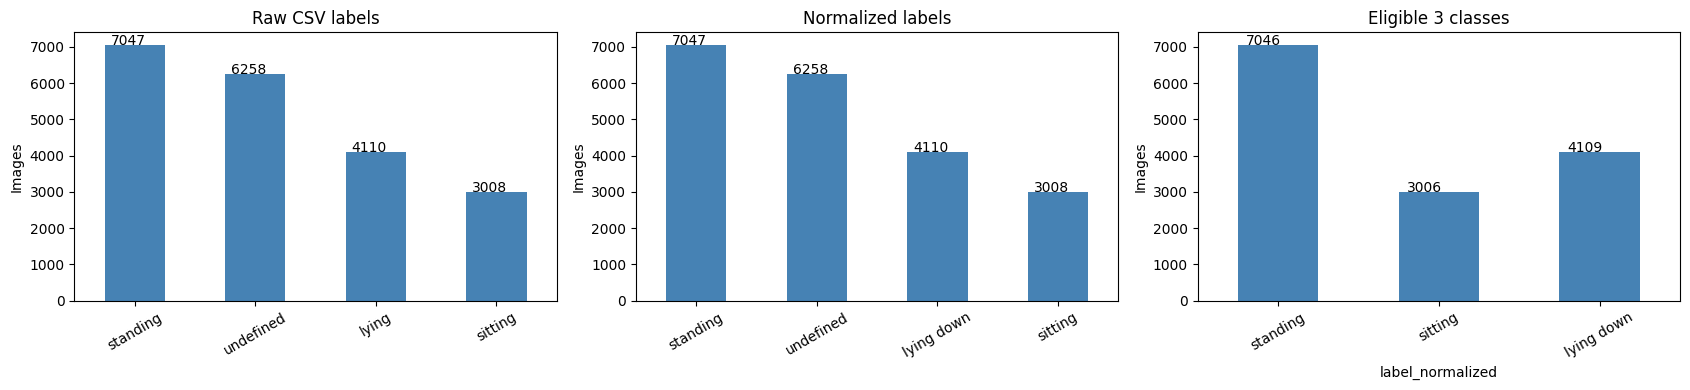

,width,height,aspect_ratio
count,20730.000,20730.000,20730.000
mean,442.533,385.737,1.188
std,142.626,124.694,0.298
min,97.000,100.000,0.394
25%,361.000,333.000,0.926
50%,500.000,375.000,1.333
75%,500.000,452.000,1.338
max,3264.000,2562.000,3.634


,width,height,aspect_ratio
label_normalized,,,
lying down,500.0,375.0,1.333
sitting,405.0,375.0,1.000
standing,500.0,375.0,1.333
undefined,500.0,375.0,1.333
unknown,393.0,375.0,1.213


,,images
source_mode,source_channels,
RGB,3,20729
RGBA,4,1


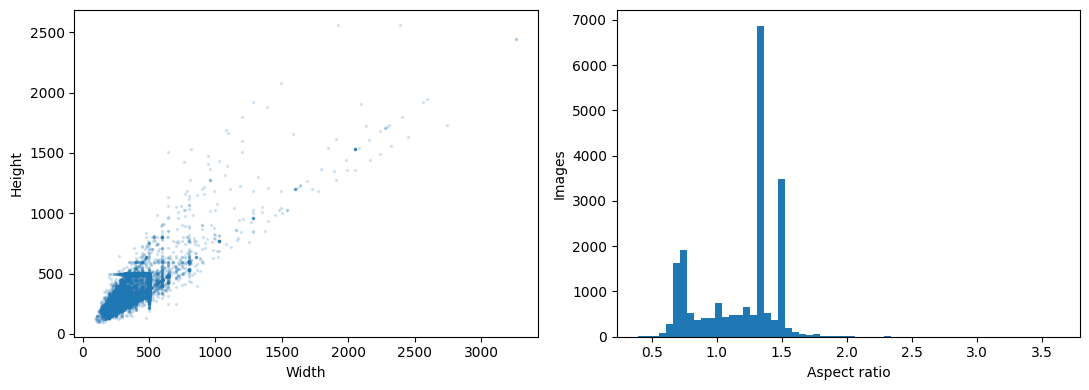

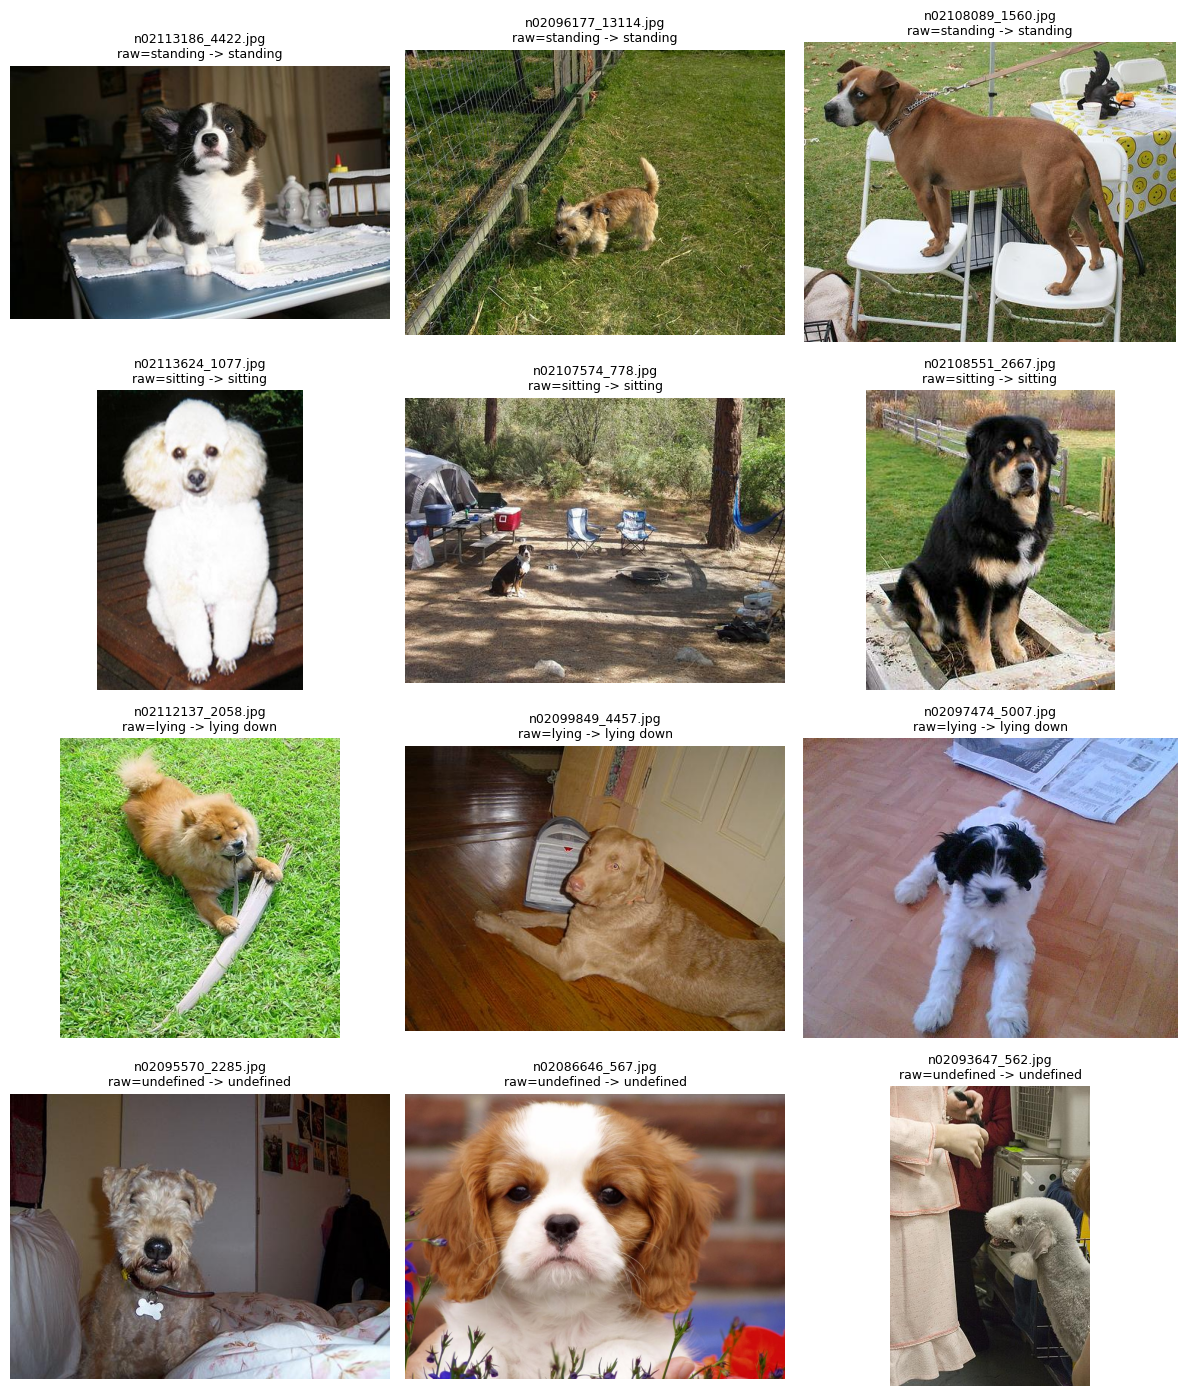

사용 가능: 14161 제외: 6569 파일 삭제: 없음
공개 분포 대비 차이: {'standing': 2904, 'sitting': -30, 'lying down': -2980, 'undefined': -49}


실측 라벨 분포가 공개 참고값과 다르다. 위 차이와 unmatched/손상/중복 수를 구분해 해석한다. 참고값에 수량을 맞추지 않는다.

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, counts, title in zip(axes, [pd.Series(raw_counts), pd.Series(normalized_counts), core_counts.reindex(LABELS)],
    ["Raw CSV labels", "Normalized labels", "Eligible 3 classes"]):
    counts.plot.bar(ax=ax, color="steelblue")
    ax.set_title(title); ax.set_ylabel("Images"); ax.tick_params(axis="x", rotation=30)
    for p in ax.patches: ax.annotate(str(int(p.get_height())), (p.get_x()+0.05, p.get_height()))
plt.tight_layout(); fig.savefig(OUTPUT_DIR / "figures" / "class_counts.png", dpi=150); plt.show()
valid = manifest.loc[manifest.image_status.eq("ok")].copy()
valid["aspect_ratio"] = valid.width / valid.height
display(valid[["width", "height", "aspect_ratio"]].describe().round(3))
display(valid.groupby("label_normalized")[["width", "height", "aspect_ratio"]].median().round(3))
display(valid.groupby(["source_mode", "source_channels"]).size().rename("images").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(valid.width, valid.height, s=2, alpha=0.15); axes[0].set(xlabel="Width", ylabel="Height")
axes[1].hist(valid.aspect_ratio, bins=60); axes[1].set(xlabel="Aspect ratio", ylabel="Images")
plt.tight_layout(); fig.savefig(OUTPUT_DIR / "figures" / "resolution.png", dpi=150); plt.show()
def open_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")
fig, axes = plt.subplots(4, 3, figsize=(12, 14))
for row_index, label in enumerate(LABELS + ["undefined"]):
    examples = manifest.loc[manifest.label_normalized.eq(label) & manifest.image_status.eq("ok")].sample(
        n=min(3, int((manifest.label_normalized.eq(label) & manifest.image_status.eq("ok")).sum())), random_state=SEED)
    for col_index in range(3):
        ax = axes[row_index, col_index]; ax.axis("off")
        if col_index >= len(examples): continue
        sample = examples.iloc[col_index]
        ax.imshow(open_rgb(EXTRACT_DIR / sample.image_path))
        ax.set_title(f"{sample.id}\nraw={sample.label_raw} -> {label}", fontsize=9)
plt.tight_layout(); fig.savefig(OUTPUT_DIR / "figures" / "label_examples.png", dpi=130); plt.show()
print("사용 가능:", audit["eligible_images"], "제외:", audit["excluded_images"], "파일 삭제: 없음")
print("공개 분포 대비 차이:", audit["difference_from_reference"])
if all(v == 0 for v in audit["difference_from_reference"].values()):
    display(Markdown("실측 라벨 분포는 데이터셋 카드의 참고 분포와 일치한다. 메타데이터 항목을 제외한 실제 사진·라벨의 연결을 검증했다."))
else:
    display(Markdown("실측 라벨 분포가 공개 참고값과 다르다. 위 차이와 unmatched/손상/중복 수를 구분해 해석한다. 참고값에 수량을 맞추지 않는다."))

## 6. Train / Validation / Test: 그룹을 보존하는 층화 분할

`load_data()`는 HF Dataset을 반환하고 `prepare_splits(data, seed)`는 DatasetDict를 반환한다.
기존 감사로 확정한 14,161장의 경로·SHA256·라벨·분할 참조가 이 노트북에 내장되어 있다.
실제 파일을 참조와 대조한 뒤 기존 Train 9,912 / Validation 2,129 / Test 2,120을 복원한다.
참조와 자료가 다르면 새로 무작위 분할하지 않고 중단한다.
공식 split이 있으면 train/validation/test로 정규화해 보존하고 없는 분할만 만드는 일반 함수도 유지한다.
공식 분할 사이에 중복 그룹이 있으면 조용히 재배치하지 않고 중단한다.
실제 CSV에 공식 분할이 없을 때는 라벨이 단일한 중복 그룹을 단위로 층화 추출한다.
그룹 크기 때문에 이미지 비율은 목표 70/15/15와 조금 다를 수 있다. 유효 3-class 이미지는 전부 사용한다.
같은 개체/연속 촬영 정보는 제공되지 않아 개체 단위 일반화를 보장할 수 없다.

In [30]:
import base64, zlib
CONFIRMED_SPLITS_B64 = "..."

def load_data():
    frame = manifest.loc[manifest.exclusion_reason.eq("")].copy()
    frame["labels"] = frame.label_normalized.map(label2id).astype(int)
    return Dataset.from_pandas(frame.reset_index(drop=True), preserve_index=False).cast_column(
        "labels", ClassLabel(names=LABELS))

def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits: raise ValueError("train 분할이 필요합니다.")
    frame = pd.concat([ds.to_pandas().assign(_provided_split=name) for name, ds in splits.items()], ignore_index=True)
    aliases = {"train": "train", "training": "train", "val": "validation", "valid": "validation",
               "validation": "validation", "test": "test", "testing": "test", "": ""}
    declared = frame.official_split.fillna("").map(aliases)
    if declared.isna().any(): raise ValueError("알 수 없는 공식 split 값. 원본 CSV 확인 필요")
    if declared.ne("").any():
        if declared.eq("").any(): raise ValueError("일부 행에만 공식 split 정보 존재")
        frame["split"] = declared
    else:
        frame["split"] = frame._provided_split
    if frame.groupby("duplicate_group").split.nunique().gt(1).any():
        raise ValueError("공식 분할 사이 중복 그룹 발견. 수동 검토 필요")
    if "train" not in set(frame.split): raise ValueError("공식 train 분할 없음")
    needed = [name for name in ["test", "validation"] if name not in set(frame.split)]
    for target in needed:
        train = frame.loc[frame.split.eq("train")]
        groups = train.groupby("duplicate_group", sort=True).labels.first().reset_index()
        # Test 생성 후 남은 train에서 validation을 뽑아 최종 목표 비율을 유지한다.
        ratio = SPLIT_RATIOS[2] if target == "test" else SPLIT_RATIOS[1] / (1-SPLIT_RATIOS[2])
        if target == "validation" and "test" not in needed:
            ratio = SPLIT_RATIOS[1] / (SPLIT_RATIOS[0]+SPLIT_RATIOS[1])
        _, held_out = train_test_split(groups, test_size=ratio, random_state=seed,
                                      stratify=groups.labels)
        frame.loc[frame.duplicate_group.isin(held_out.duplicate_group), "split"] = target
    result = DatasetDict({name: Dataset.from_pandas(frame.loc[frame.split.eq(name)].drop(
        columns="_provided_split").reset_index(drop=True), preserve_index=False).cast_column(
            "labels", ClassLabel(names=LABELS)) for name in ["train", "validation", "test"]})
    for a, b in combinations(result, 2):
        for field in ["sha256", "pixel_sha256", "duplicate_group"]:
            assert not set(result[a][field]) & set(result[b][field]), f"{field} 누출: {a}/{b}"
    assert sum(len(ds) for ds in result.values()) == len(frame)
    for ds in result.values(): assert set(ds["labels"]) == set(range(3))
    return result

def restore_confirmed_splits(data):
    reference = pd.DataFrame(json.loads(zlib.decompress(base64.b64decode(CONFIRMED_SPLITS_B64)).decode("utf-8")))
    frame = data.to_pandas()
    if frame.image_path.duplicated().any() or set(frame.image_path) != set(reference.image_path):
        raise ValueError("확정된 14,161장과 실제 사용 대상의 경로가 다름. 임의 재분할 금지")
    joined = frame.merge(reference, on="image_path", suffixes=("", "_confirmed"), validate="one_to_one")
    for field in ["sha256", "label_normalized"]:
        if not joined[field].eq(joined[field+"_confirmed"]).all():
            paths = joined.loc[joined[field].ne(joined[field+"_confirmed"]), "image_path"].tolist()
            raise ValueError(f"확정 분할의 {field} 불일치: {paths}")
    result = DatasetDict()
    for name in ["train", "validation", "test"]:
        selected = joined.loc[joined.split_confirmed.eq(name), frame.columns].copy()
        selected["split"] = name
        result[name] = Dataset.from_pandas(selected.reset_index(drop=True), preserve_index=False).cast_column(
            "labels", ClassLabel(names=LABELS))
    print("기존 확정 분할 복원:", {name: len(ds) for name,ds in result.items()}, "무작위 재분할 없음")
    return result

raw = prepare_splits(restore_confirmed_splits(load_data()))
split_map = {row["image_path"]: name for name, ds in raw.items() for row in ds}
manifest["split"] = manifest.image_path.map(split_map).fillna("excluded")
manifest.to_csv(EXTRACT_DIR / "dataset_manifest.csv", index=False)
split_table = pd.crosstab(manifest.loc[manifest.split.ne("excluded")].split,
                         manifest.loc[manifest.split.ne("excluded")].label_normalized).reindex(
    index=["train", "validation", "test"], columns=LABELS, fill_value=0)
display(split_table.assign(total=split_table.sum(axis=1)))
print("실제 split 비율:", (split_table.sum(axis=1)/split_table.values.sum()).round(5).to_dict())
print("SHA256/RGB pixel/group split 누출 검사: 통과")
audit["split_counts"] = split_table.to_dict("index")
audit["split_totals"] = {k: len(v) for k,v in raw.items()}
audit["official_split_values"] = sorted(set(manifest.official_split))
audit["split_seed"] = SEED
audit["split_fingerprint"] = hashlib.sha256(manifest[["image_path", "sha256", "split"]].to_csv(index=False).encode()).hexdigest()
data_quality_ready, gate_blockers = training_data_gate(manifest, audit)
audit["data_quality_ready"], audit["gate_blockers"] = data_quality_ready, gate_blockers
assert not manifest.loc[manifest.breed_folder.eq("validation"), "split"].isin(["train", "validation", "test"]).any()
audit["held_and_excluded_counts"] = {
    "held_outside_splits": int((manifest.review_decision.eq("hold") & manifest.split.eq("excluded")).sum()),
    "excluded_including_hold": int(manifest.split.eq("excluded").sum()),
    "excluded_without_hold": int((manifest.split.eq("excluded") & manifest.review_decision.ne("hold")).sum()),
    "by_reason": manifest.loc[manifest.split.eq("excluded")].exclusion_reason.value_counts().to_dict(),
}
pd.DataFrame(audit["selected_label_source_checks"]["errors"], columns=["image_path", "reason"]).to_csv(
    EXTRACT_DIR / "selected_label_link_errors.csv", index=False)
write_json(EXTRACT_DIR / "data_audit.json", audit)
print("최종 사용 데이터 품질 게이트:", data_quality_ready, "차단 사유:", gate_blockers)
print("사용 대상 미확인 라벨:", audit["selected_unverified_images"], "사용 대상 밖 보류:", audit["held_images_outside_selection"])
if not data_quality_ready:
    raise RuntimeError(f"학습 중단: {gate_blockers}. data_audit.json과 selected_label_link_errors.csv 확인")
display(raw)

Casting the dataset:   0%|          | 0/14161 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9912 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2129 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2120 [00:00<?, ? examples/s]

기존 확정 분할 복원: {'train': 9912, 'validation': 2129, 'test': 2120} 무작위 재분할 없음


Casting the dataset:   0%|          | 0/9912 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2129 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/2120 [00:00<?, ? examples/s]

label_normalized,standing,sitting,lying down,total
split,,,,
train,4932,2100,2880,9912
validation,1060,454,615,2129
test,1054,452,614,2120


실제 split 비율: {'train': 0.69995, 'validation': 0.15034, 'test': 0.14971}
SHA256/RGB pixel/group split 누출 검사: 통과
최종 사용 데이터 품질 게이트: True 차단 사유: []
사용 대상 미확인 라벨: 0 사용 대상 밖 보류: 157


DatasetDict({
    train: Dataset({
        features: ['image_path', 'source_csv', 'id', 'label_raw', 'label_normalized', 'breed_folder', 'match_status', 'official_split', 'sha256', 'pixel_sha256', 'phash', 'width', 'height', 'source_mode', 'source_channels', 'image_status', 'image_error', 'unmatched_reason', 'duplicate_group', 'exclusion_reason', 'split', 'match_method', 'matched_source_id', 'review_decision', 'labels'],
        num_rows: 9912
    })
    validation: Dataset({
        features: ['image_path', 'source_csv', 'id', 'label_raw', 'label_normalized', 'breed_folder', 'match_status', 'official_split', 'sha256', 'pixel_sha256', 'phash', 'width', 'height', 'source_mode', 'source_channels', 'image_status', 'image_error', 'unmatched_reason', 'duplicate_group', 'exclusion_reason', 'split', 'match_method', 'matched_source_id', 'review_decision', 'labels'],
        num_rows: 2129
    })
    test: Dataset({
        features: ['image_path', 'source_csv', 'id', 'label_raw', 'label_normal

## 7. 사전학습 ViT·고정 초기 head·전처리

모델은 [google/vit-base-patch16-224-in21k](https://huggingface.co/google/vit-base-patch16-224-in21k)를 사용한다.
ImageNet-21k 사전학습 모델이며 이번 자세용 head는 새로 초기화한다.
Stanford Dogs가 ImageNet에서 유래하므로 사전학습 이미지와 평가 이미지가 겹칠 가능성도 한계다.
Baseline과 LoRA는 같은 seed와 초기 classifier state를 사용한다. Baseline 학습 결과로 LoRA를 초기화하지 않는다.
Train에만 좌우 반전·±5도 회전·약한 색 변화를 적용하고, 평가·pipeline은 동일 processor의 고정 전처리를 사용한다.
원본 RGB를 유지해 필요할 때 로드하므로 2만 장의 224×224 tensor를 RAM에 미리 쌓지 않는다.

In [31]:
from torchvision import transforms as T
train_augmentation = T.Compose([T.RandomHorizontalFlip(p=0.5), T.RandomRotation(degrees=5),
                               T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)])
initial_classifier_state = None
resolved_revision = MODEL_REVISION
model_ready, model_error = False, None
baseline_model, processor = None, None
def load_model_and_processor():
    global initial_classifier_state, resolved_revision
    set_seed(SEED)
    proc = AutoImageProcessor.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=False)
    current = AutoModelForImageClassification.from_pretrained(
        MODEL_ID, revision=resolved_revision, num_labels=3, id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)
    resolved_revision = getattr(current.config, "_commit_hash", None) or resolved_revision
    if initial_classifier_state is None:
        initial_classifier_state = {k: v.detach().cpu().clone() for k,v in current.classifier.state_dict().items()}
    else:
        current.classifier.load_state_dict(initial_classifier_state)
    return current, proc

def preprocess(example):
    image = open_rgb(EXTRACT_DIR / example["image_path"])
    return {"pixel_values": processor(images=image, return_tensors="pt")["pixel_values"][0],
            "labels": int(example["labels"])}

class PoseDataset(torch.utils.data.Dataset):
    def __init__(self, data, training=False):
        self.data, self.training = data, training
    def __len__(self): return len(self.data)
    def __getitem__(self, index):
        example = self.data[index]
        if not self.training: return preprocess(example)
        image = train_augmentation(open_rgb(EXTRACT_DIR / example["image_path"]))
        return {"pixel_values": processor(images=image, return_tensors="pt")["pixel_values"][0],
                "labels": int(example["labels"])}

if RUN_MODE == "train" or CHECK_PRETRAINED_MODEL:
    try:
        baseline_model, processor = load_model_and_processor()
        model_ready = True
        display(processor)
        print("모델 로드 성공. 실제 revision:", resolved_revision)
        sample = preprocess(raw["train"][0])
        baseline_model.eval()
        with torch.no_grad():
            probe = baseline_model(pixel_values=sample["pixel_values"].unsqueeze(0)).logits
        assert probe.shape == (1, 3) and torch.isfinite(probe).all()
        print("실제 Train 이미지 forward 점검:", tuple(sample["pixel_values"].shape), "->", tuple(probe.shape))
        print("새 head의 학습 전 출력이므로 성능 지표로 보고하지 않음")
    except Exception as exc:
        model_ready = False
        baseline_model = None
        model_error = f"{type(exc).__name__}: {exc}"
        print("모델 다운로드/초기화 실패:", model_error)
        write_json(OUTPUT_DIR / "evaluation" / "model_load_error.json", {"model": MODEL_ID, "error": model_error})
        if RUN_MODE == "train": raise
if model_ready:
    prepared = {name: PoseDataset(ds, training=name=="train") for name, ds in raw.items()}
    print("Train 전용 augmentation:", train_augmentation)
    print("평가 tensor:", tuple(prepared["validation"][0]["pixel_values"].shape))
    for p in baseline_model.parameters(): p.requires_grad = False
    for p in baseline_model.classifier.parameters(): p.requires_grad = True
    assert all(n.startswith("classifier.") for n,p in baseline_model.named_parameters() if p.requires_grad)
    total = sum(p.numel() for p in baseline_model.parameters())
    trainable = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
    print(f"Baseline trainable: {trainable:,}/{total:,} ({100*trainable/total:.4f}%)")
else:
    prepared = None
    print("모델 미준비: 데이터 감사는 유지. 학습·추론은 미실행")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViTImageProcessorPil {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

모델 로드 성공. 실제 revision: main
실제 Train 이미지 forward 점검: (3, 224, 224) -> (1, 3)
새 head의 학습 전 출력이므로 성능 지표로 보고하지 않음
Train 전용 augmentation: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-5.0, 5.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=(-0.02, 0.02))
)
평가 tensor: (3, 224, 224)
Baseline trainable: 2,307/85,800,963 (0.0027%)


## 8. LoRA 대상과 학습 가능 파라미터 검사

실제 `named_modules()`의 모든 Linear 이름을 조사하고 각 ViT 층의 attention 내부에서만 Q/K/V를 검증한다.
`encoder.layer` + `query/key/value`, `layers` + `q_proj/k_proj/v_proj` 구조를 구분해 Q와 V만 선택한다.
기본 ViT-Base는 12개 층 × Q 1개/V 1개 = 총 24개여야 한다. K나 fused qkv 전체는 대상으로 삼지 않는다.
구조/개수/크기 검증 실패 시 실제 Linear 이름을 오류에 포함하고 학습을 중단한다.
classifier는 `modules_to_save`로 학습·저장한다. `task_type`을 텍스트용으로 지정하지 않고 PEFT의 일반 모델 래퍼를 사용한다.
학습 가능한 항목이 LoRA와 저장용 classifier 이외에 존재하면 중단한다.

In [32]:
def discover_vit_qv_modules(model):
    if model is None: raise ValueError("모델이 없음: 모델 로딩 셀부터 다시 실행하세요.")
    if isinstance(model, PeftModel) or any(hasattr(module, "lora_A") for module in model.modules()):
        raise ValueError("이미 LoRA가 적용된 모델입니다. 모델 로딩 셀부터 재실행해 새 모델에 한 번만 적용하세요.")
    named = dict(model.named_modules())
    linear_names = [name for name,module in named.items() if isinstance(module, torch.nn.Linear)]
    print("실제 Linear 모듈 목록:", *linear_names, sep="\n")
    def fail(message):
        raise ValueError(f"ViT Q/V 검증 실패: {message}; transformers={transformers.__version__}; "
                         f"실제 Linear 모듈={linear_names}")
    vit = getattr(model, "vit", None)
    if vit is None or getattr(model.config, "model_type", None) != "vit": fail("ViT backbone 없음")
    if hasattr(vit, "encoder") and hasattr(vit.encoder, "layer"):
        layers, layout = vit.encoder.layer, "vit.encoder.layer"
    elif hasattr(vit, "layers"):
        layers, layout = vit.layers, "vit.layers"
    elif hasattr(vit, "encoder") and hasattr(vit.encoder, "layers"):
        layers, layout = vit.encoder.layers, "vit.encoder.layers"
    else: fail("지원되는 실제 ViT layer container 없음")
    expected = model.config.num_hidden_layers
    if len(layers) != expected: fail(f"층 수 {len(layers)} != config {expected}")
    module_names = {id(module): name for name,module in named.items()}
    targets, per_layer = [], []
    for layer_index, layer in enumerate(layers):
        attention = getattr(layer, "attention", None)
        if attention is None: fail(f"layer {layer_index}: attention 없음")
        projections = [(name,module) for name,module in attention.named_modules() if isinstance(module, torch.nn.Linear)]
        profiles = []
        for query,key,value in [("query", "key", "value"), ("q_proj", "k_proj", "v_proj")]:
            found = {role: [(name,module) for name,module in projections if name.rsplit(".",1)[-1]==role]
                     for role in [query,key,value]}
            if all(len(found[role])==1 for role in found): profiles.append((query,key,value,found))
        if len(profiles) != 1: fail(f"layer {layer_index}: 유일한 개별 Q/K/V 선형층을 찾지 못함. fused qkv 사용하지 않음")
        query,key,value,found = profiles[0]
        selected = [found[role][0] for role in [query,key,value]]
        if len({name.rsplit(".",1)[0] if "." in name else "" for name,module in selected}) != 1:
            fail(f"layer {layer_index}: Q/K/V의 parent가 다름")
        if any(module.in_features!=model.config.hidden_size or module.out_features!=model.config.hidden_size for name,module in selected):
            fail(f"layer {layer_index}: Q/K/V 입출력 차원이 hidden_size와 다름")
        q_name, k_name, v_name = [module_names[id(module)] for name,module in selected]
        targets.extend([q_name,v_name])
        per_layer.append({"layer": layer_index, "query": q_name, "value": v_name,
                          "query_count": 1, "value_count": 1, "key_excluded": k_name})
    if len(targets) != 2*expected or len(set(targets)) != 2*expected:
        fail(f"대상 {len(targets)}개 != {expected*2}, 중복/누락 확인 필요")
    report = {"layout": layout, "layers": expected, "query_count": len(per_layer), "value_count": len(per_layer),
              "target_modules": targets, "per_layer": per_layer, "transformers": transformers.__version__}
    model._dogpose_qv_report = report
    display(pd.DataFrame(per_layer))
    print(f"LoRA 대상 검증: Query {len(per_layer)}, Value {len(per_layer)}, 합계 {len(targets)}; layout={layout}")
    return targets

def make_lora_config(model):
    names = discover_vit_qv_modules(model)
    return LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                      target_modules=names, modules_to_save=["classifier"], bias="none")

def assert_lora_trainables(model):
    names = [n for n,p in model.named_parameters() if p.requires_grad]
    assert any("lora_A" in n for n in names) and any("lora_B" in n for n in names)
    assert any("classifier.modules_to_save" in n for n in names)
    assert all("lora_" in n or "classifier.modules_to_save" in n for n in names), names
    inserted = [name for name,module in model.named_modules() if hasattr(module, "lora_A") and hasattr(module, "lora_B")]
    expected = 2*model.config.num_hidden_layers
    assert len(inserted)==expected, f"PEFT 삽입 수 불일치: {inserted} ({len(inserted)} != {expected})"
    print("PEFT 삽입 확인:", len(inserted), "개 Q/V + 저장용 classifier 학습 가능")
    model.print_trainable_parameters()
    return names

# audit 모드에서는 Baseline 모델을 재사용해 LoRA 삽입/forward만 검사한다.
# 이 모델은 학습하거나 학습된 adapter로 저장하지 않는다.
if model_ready and RUN_MODE == "audit":
    audit_lora_model = get_peft_model(baseline_model, make_lora_config(baseline_model))
    audited_trainables = assert_lora_trainables(audit_lora_model)
    audit_lora_model.eval()
    with torch.no_grad():
        logits = audit_lora_model(pixel_values=preprocess(raw["train"][0])["pixel_values"].unsqueeze(0)).logits
    assert logits.shape == (1,3) and torch.isfinite(logits).all()
    write_json(OUTPUT_DIR / "evaluation" / "lora_module_audit.json", {
        **audit_lora_model.get_base_model()._dogpose_qv_report, "model_id": MODEL_ID,
        "model_revision": resolved_revision, "peft": peft.__version__,
        "peft_inserted_modules": 2*audit_lora_model.config.num_hidden_layers,
        "classifier_trainable_verified": True, "trainable_scope_verified": True,
        "forward_shape": list(logits.shape), "training_executed": False,
        "executed_utc": datetime.now(timezone.utc).isoformat()})
    print("실제 pretrained ViT LoRA 삽입/forward 검사 통과. 학습/최종 Test/학습된 adapter 저장: 미실행")
    del audit_lora_model, baseline_model
    baseline_model = None
    gc.collect()

## 9. Trainer와 학습 설정

Train 분할에서만 `N / (3 × 클래스 수)`로 가중치를 계산해 cross entropy에 적용한다.
Validation Macro-F1 기준으로 가장 좋은 **학습 가능 파라미터**를 메모리에 보관하고 종료 시 복원한다.
2회 연속 개선이 없으면 조기 종료한다. 고정 backbone은 저장하지 않아 checkpoint의 중복을 줄인다.
Baseline과 LoRA의 optimizer·학습률·epoch·augmentation은 동일하다.

In [33]:
from transformers import TrainerCallback
from safetensors.torch import save_file, load_file
train_counts = np.bincount(raw["train"]["labels"], minlength=3)
class_weights = torch.tensor(len(raw["train"]) / (3 * train_counts), dtype=torch.float32)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
experiment_config = {
    "run_id": RUN_ID, "run_mode": RUN_MODE, "model_id": MODEL_ID, "model_revision": resolved_revision,
    "input_size": dict(processor.size) if processor else "미확인", "split_sizes": {k: len(v) for k,v in raw.items()},
    "batch_size": BATCH_SIZE, "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "optimizer": OPTIMIZER,
    "weight_decay": WEIGHT_DECAY, "seed": SEED,
    "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_dropout": LORA_DROPOUT,
    "class_weighting": "train N/(3*n_c), weighted cross entropy", "class_weights": class_weights.tolist(),
    "train_class_counts": train_counts.tolist(), "device": DEVICE, "label2id": label2id,
    "split_fingerprint": audit["split_fingerprint"], "versions": versions,
    "selection": "validation macro-F1 best trainable state; patience=2",
}
display(pd.Series(experiment_config, name="학습 설정").to_frame())
write_json(OUTPUT_DIR / "evaluation" / "experiment_config.json", experiment_config)

def metric_values(targets, predictions):
    return {"accuracy": float(accuracy_score(targets, predictions)),
            "macro_f1": float(f1_score(targets, predictions, labels=list(id2label), average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(targets, predictions, labels=list(id2label), average="weighted", zero_division=0))}

class BestTrainableState(TrainerCallback):
    def __init__(self, patience=2):
        self.best, self.bad_epochs, self.patience, self.weights, self.best_epoch = -np.inf, 0, patience, None, None
    def on_evaluate(self, args, state, control, model=None, metrics=None, **kwargs):
        value = metrics["eval_macro_f1"]
        if value > self.best:
            self.best, self.bad_epochs, self.best_epoch = value, 0, state.epoch
            self.weights = {n: p.detach().cpu().clone() for n,p in model.named_parameters() if p.requires_grad}
        else:
            self.bad_epochs += 1
            if self.bad_epochs >= self.patience: control.should_training_stop = True
        return control
    def on_train_end(self, args, state, control, model=None, **kwargs):
        if self.weights is None: raise RuntimeError("Validation 결과 없음: best state를 복원할 수 없음")
        with torch.no_grad():
            for name, param in model.named_parameters():
                if name in self.weights: param.copy_(self.weights[name].to(param.device))
        print(f"Validation best state 복원: epoch={self.best_epoch}, macro-F1={self.best:.6f}")

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.model_accepts_loss_kwargs = False
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(pixel_values=inputs["pixel_values"])
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels,
                                                 weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def make_trainer(model, processor, train_data, validation_data):
    kind = "lora" if isinstance(model, PeftModel) else "baseline"
    bf16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
    args = TrainingArguments(
        output_dir=str(OUTPUT_DIR / ("lora_adapter" if kind=="lora" else "baseline") / RUN_ID / "trainer"),
        learning_rate=LEARNING_RATE, num_train_epochs=EPOCHS, optim=OPTIMIZER, weight_decay=WEIGHT_DECAY,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_strategy="epoch", save_strategy="no", logging_strategy="steps", logging_steps=20,
        bf16=bf16, fp16=DEVICE=="cuda" and not bf16, use_cpu=DEVICE=="cpu",
        remove_unused_columns=False, label_names=["labels"], report_to="none",
        seed=SEED, data_seed=SEED, dataloader_num_workers=0, dataloader_pin_memory=DEVICE=="cuda")
    return WeightedTrainer(model=model, args=args, train_dataset=train_data, eval_dataset=validation_data,
        processing_class=processor, data_collator=default_data_collator, class_weights=class_weights,
        compute_metrics=lambda result: metric_values(result.label_ids, result.predictions.argmax(-1)),
        callbacks=[BestTrainableState(patience=2)])

training_completed = False
history = {}
baseline_dir = OUTPUT_DIR / "baseline" / RUN_ID
adapter_dir = OUTPUT_DIR / "lora_adapter" / RUN_ID
lora_model = None
if RUN_MODE == "train" and data_quality_ready:
    data_quality_ready, gate_blockers = training_data_gate(manifest, audit)
    audit["data_quality_ready"], audit["gate_blockers"] = data_quality_ready, gate_blockers
    write_json(EXTRACT_DIR / "data_audit.json", audit)
    if not data_quality_ready: raise RuntimeError(f"학습 직전 품질 재검사 실패: {gate_blockers}")
    if not model_ready: raise RuntimeError("모델 로드 실패: 학습 불가")
    set_seed(SEED)
    baseline_trainer = make_trainer(baseline_model, processor, prepared["train"], prepared["validation"])
    baseline_trainer.train()
    history["baseline"] = baseline_trainer.state.log_history
    baseline_dir.mkdir(parents=True, exist_ok=True)
    save_file({k: v.detach().cpu().contiguous() for k,v in baseline_model.classifier.state_dict().items()},
              str(baseline_dir / "classifier.safetensors"))
    baseline_model.config.save_pretrained(baseline_dir)
    processor.save_pretrained(baseline_dir)
    write_json(baseline_dir / "training_config.json", experiment_config)
    baseline_model.to("cpu")
    del baseline_trainer
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    fresh_model, _ = load_model_and_processor()
    for k,v in fresh_model.classifier.state_dict().items():
        torch.testing.assert_close(v.cpu(), initial_classifier_state[k])
    lora_model = get_peft_model(fresh_model, make_lora_config(fresh_model))
    assert_lora_trainables(lora_model)
    set_seed(SEED)
    lora_trainer = make_trainer(lora_model, processor, prepared["train"], prepared["validation"])
    lora_trainer.train()
    history["lora"] = lora_trainer.state.log_history
    adapter_dir.mkdir(parents=True, exist_ok=True)
    lora_model.save_pretrained(adapter_dir, safe_serialization=True)
    lora_model.config.save_pretrained(adapter_dir)
    processor.save_pretrained(adapter_dir)
    write_json(adapter_dir / "training_config.json", experiment_config)
    write_json(adapter_dir / "label_mapping.json", {"id2label": id2label, "label2id": label2id})
    del lora_trainer
    lora_model.to("cpu")
    training_completed = True
    print("Baseline/LoRA 학습 및 Validation best 복원 완료. 이제 고정 Test를 각각 한 번 평가한다.")
else:
    print("Baseline 학습: 미실행 / LoRA 학습: 미실행")
    print("사유:", "미매칭/라벨 감사 검토 필요" if not data_quality_ready else "audit 모드: CPU 전체 학습 생략")
write_json(OUTPUT_DIR / "evaluation" / "training_history.json", history)

,학습 설정
run_id,20261126T035657_418945Z
run_mode,train
model_id,google/vit-base-patch16-224-in21k
model_revision,main
input_size,"{'height': 224, 'width': 224}"
split_sizes,"{'train': 9912, 'validation': 2129, 'test': 2120}"
batch_size,8
gradient_accumulation_steps,2
epochs,3
learning_rate,0.0005


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.905213,0.923443,0.629873,0.590717,0.634999
2,0.910564,0.879798,0.651480,0.615106,0.656984
3,0.889618,0.868593,0.659465,0.619893,0.662977


Validation best state 복원: epoch=3.0, macro-F1=0.619893


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


실제 Linear 모듈 목록:
vit.layers.0.attention.q_proj
vit.layers.0.attention.k_proj
vit.layers.0.attention.v_proj
vit.layers.0.attention.o_proj
vit.layers.0.mlp.fc1
vit.layers.0.mlp.fc2
vit.layers.1.attention.q_proj
vit.layers.1.attention.k_proj
vit.layers.1.attention.v_proj
vit.layers.1.attention.o_proj
vit.layers.1.mlp.fc1
vit.layers.1.mlp.fc2
vit.layers.2.attention.q_proj
vit.layers.2.attention.k_proj
vit.layers.2.attention.v_proj
vit.layers.2.attention.o_proj
vit.layers.2.mlp.fc1
vit.layers.2.mlp.fc2
vit.layers.3.attention.q_proj
vit.layers.3.attention.k_proj
vit.layers.3.attention.v_proj
vit.layers.3.attention.o_proj
vit.layers.3.mlp.fc1
vit.layers.3.mlp.fc2
vit.layers.4.attention.q_proj
vit.layers.4.attention.k_proj
vit.layers.4.attention.v_proj
vit.layers.4.attention.o_proj
vit.layers.4.mlp.fc1
vit.layers.4.mlp.fc2
vit.layers.5.attention.q_proj
vit.layers.5.attention.k_proj
vit.layers.5.attention.v_proj
vit.layers.5.attention.o_proj
vit.layers.5.mlp.fc1
vit.layers.5.mlp.fc2
vit.layers.

,layer,query,value,query_count,value_count,key_excluded
0,0,vit.layers.0.attention.q_proj,vit.layers.0.attention.v_proj,1,1,vit.layers.0.attention.k_proj
1,1,vit.layers.1.attention.q_proj,vit.layers.1.attention.v_proj,1,1,vit.layers.1.attention.k_proj
2,2,vit.layers.2.attention.q_proj,vit.layers.2.attention.v_proj,1,1,vit.layers.2.attention.k_proj
3,3,vit.layers.3.attention.q_proj,vit.layers.3.attention.v_proj,1,1,vit.layers.3.attention.k_proj
4,4,vit.layers.4.attention.q_proj,vit.layers.4.attention.v_proj,1,1,vit.layers.4.attention.k_proj
5,5,vit.layers.5.attention.q_proj,vit.layers.5.attention.v_proj,1,1,vit.layers.5.attention.k_proj
6,6,vit.layers.6.attention.q_proj,vit.layers.6.attention.v_proj,1,1,vit.layers.6.attention.k_proj
7,7,vit.layers.7.attention.q_proj,vit.layers.7.attention.v_proj,1,1,vit.layers.7.attention.k_proj
8,8,vit.layers.8.attention.q_proj,vit.layers.8.attention.v_proj,1,1,vit.layers.8.attention.k_proj
9,9,vit.layers.9.attention.q_proj,vit.layers.9.attention.v_proj,1,1,vit.layers.9.attention.k_proj


LoRA 대상 검증: Query 12, Value 12, 합계 24; layout=vit.layers
PEFT 삽입 확인: 24 개 Q/V + 저장용 classifier 학습 가능
trainable params: 297,219 || all params: 86,098,182 || trainable%: 0.3452


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.191461,0.230971,0.917332,0.905054,0.918289
2,0.268897,0.204456,0.931893,0.920983,0.932285
3,0.152449,0.209206,0.933302,0.922256,0.933558


Validation best state 복원: epoch=3.0, macro-F1=0.922256
Baseline/LoRA 학습 및 Validation best 복원 완료. 이제 고정 Test를 각각 한 번 평가한다.


## 10. 학습 곡선과 고정 Test 최종 평가

`get_targets`, `predict_labels`, `accuracy`, `evaluate_model`은 스켈레톤의 서명을 유지한다.
pipeline은 원본 RGB 이미지만 입력받고, 정답은 지표 계산에만 사용한다.
실제 PEFT base model에 삽입된 LoRA는 유지한 채 pipeline에 전달한다.
이미지는 batch 단위로 로드해 메모리를 제한한다. Test는 두 모델 학습과 Validation 선택이 끝난 뒤 한 번씩만 평가한다.

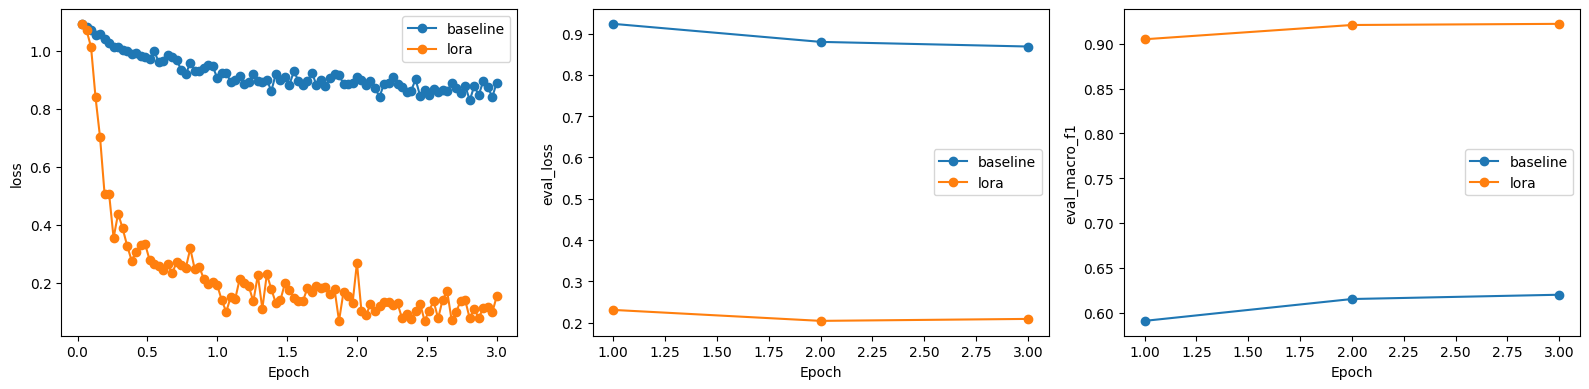

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,accuracy,macro_f1,weighted_f1
Baseline head-only,0.642453,0.605847,0.646854
LoRA + head,0.938679,0.928112,0.938752


baseline classification report


,precision,recall,f1-score,support
standing,0.767911,0.722011,0.744254,1054.000000
sitting,0.418288,0.475664,0.445135,452.000000
lying down,0.627642,0.628664,0.628153,614.000000
accuracy,0.642453,0.642453,0.642453,0.642453
macro avg,0.604614,0.608780,0.605847,2120.000000
weighted avg,0.652744,0.642453,0.646854,2120.000000


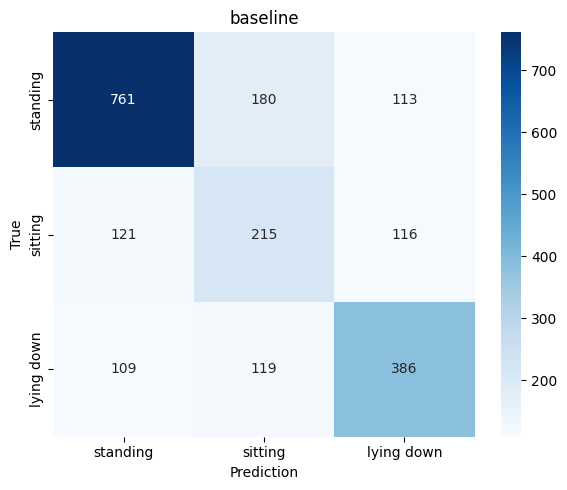

lora classification report


,precision,recall,f1-score,support
standing,0.962963,0.962049,0.962506,1054.000000
sitting,0.877462,0.887168,0.882288,452.000000
lying down,0.942623,0.936482,0.939542,614.000000
accuracy,0.938679,0.938679,0.938679,0.938679
macro avg,0.927683,0.928567,0.928112,2120.000000
weighted avg,0.938843,0.938679,0.938752,2120.000000


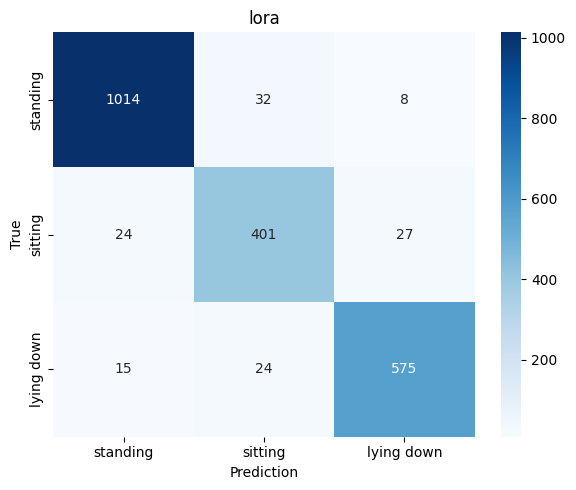

Test 클래스별 수량: {'standing': 1054, 'sitting': 452, 'lying down': 614}


In [34]:
if training_completed:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for kind, logs in history.items():
        log = pd.DataFrame(logs)
        for ax, column in zip(axes, ["loss", "eval_loss", "eval_macro_f1"]):
            if column in log:
                subset = log.loc[log[column].notna()]
                ax.plot(subset.epoch, subset[column], marker="o", label=kind)
                ax.set(xlabel="Epoch", ylabel=column); ax.legend()
    plt.tight_layout(); fig.savefig(OUTPUT_DIR / "figures" / "learning_curves.png", dpi=150); plt.show()
else:
    print("학습 곡선: 미실행 (학습 로그 없음)")

def get_targets(test_data):
    return [int(example["labels"]) for example in test_data]

def predict_labels(current_model, processor, test_data):
    current_model.eval()
    base = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    classifier = pipeline("image-classification", model=base, image_processor=processor,
                          device=0 if DEVICE=="cuda" else -1)
    predictions, confidences = [], []
    for start in range(0, len(test_data), BATCH_SIZE):
        images = [open_rgb(EXTRACT_DIR / test_data[i]["image_path"])
                  for i in range(start, min(start+BATCH_SIZE, len(test_data)))]
        with torch.inference_mode():
            results = classifier(images, batch_size=BATCH_SIZE, top_k=1)
        predictions.extend(label2id[output[0]["label"]] for output in results)
        confidences.extend(float(output[0]["score"]) for output in results)
    current_model._last_prediction_confidences = confidences
    return predictions

def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a,b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    assert len(targets) == len(test_data) == len(predictions)
    metrics = metric_values(targets, predictions)
    assert np.isclose(metrics["accuracy"], accuracy(targets, predictions))
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets, "prediction": predictions,
        "image_path": [row["image_path"] for row in test_data],
        "confidence": current_model._last_prediction_confidences})
    return metrics, table

evaluation_completed = False
before_metrics, after_metrics = None, None
if training_completed:
    before_metrics, before = evaluate_model(baseline_model, processor, raw["test"])
    baseline_model.to("cpu")
    if DEVICE == "cuda": torch.cuda.empty_cache()
    after_metrics, after = evaluate_model(lora_model, processor, raw["test"])
    lora_model.to("cpu")
    assert before[["sample_id", "target", "image_path"]].equals(after[["sample_id", "target", "image_path"]])
    comparison_metrics = pd.DataFrame({"Baseline head-only": before_metrics, "LoRA + head": after_metrics}).T
    display(comparison_metrics)
    comparison_metrics.to_csv(OUTPUT_DIR / "evaluation" / "metrics.csv")
    reports, matrices = {}, {}
    for kind, table in [("baseline", before), ("lora", after)]:
        report = classification_report(table.target, table.prediction, labels=list(id2label),
                                       target_names=LABELS, output_dict=True, zero_division=0)
        cm = confusion_matrix(table.target, table.prediction, labels=list(id2label))
        reports[kind], matrices[kind] = report, cm.tolist()
        print(kind, "classification report")
        display(pd.DataFrame(report).T)
        pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "evaluation" / f"{kind}_classification_report.csv")
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt="d", xticklabels=LABELS, yticklabels=LABELS, cmap="Blues", ax=ax)
        ax.set(xlabel="Prediction", ylabel="True", title=kind)
        plt.tight_layout(); fig.savefig(OUTPUT_DIR / "figures" / f"{kind}_confusion_matrix.png", dpi=150); plt.show()
    print("Test 클래스별 수량:", dict(Counter(id2label[x] for x in before.target)))
    write_json(OUTPUT_DIR / "evaluation" / "test_results.json", {"baseline": before_metrics,
        "lora": after_metrics, "reports": reports, "confusion_matrices": matrices,
        "config": experiment_config, "test_evaluations_per_model": 1})
    evaluation_completed = True
else:
    display(pd.DataFrame({"Baseline": ["미실행"]*3, "LoRA": ["미실행"]*3},
                         index=["Accuracy", "Macro-F1", "Weighted-F1"]))
    print("Confusion Matrix / classification report / Test 예측: 미실행")

## 11. 동일 Test 이미지 최소 5개 예측 비교

전체 Test 예측을 저장한 뒤 시각화할 사례만 선택한다. 오답과 정답이 있으면 각각 포함하고 나머지는 고정 seed로 고른다.
사례 선택은 모델 재학습/설정 선택에 쓰지 않는다. confidence는 softmax 점수이며 보정된 확률이나 안전성 보증이 아니다.

,sample_id,target,baseline,image_path,baseline_confidence,lora,lora_confidence,lora_correct,target_label,baseline_label,lora_label
920,920,1,0,images/n02097298-Scotch_terrier/n02097298_2976...,0.467239,0,0.514234,False,sitting,standing,standing
948,948,2,0,images/n02097474-Tibetan_terrier/n02097474_481...,0.498962,2,0.991694,True,lying down,standing,lying down
1567,1567,1,1,images/n02108000-EntleBucher/n02108000_157.jpg,0.436111,1,0.989383,True,sitting,sitting,sitting
1102,1102,1,1,images/n02099849-Chesapeake_Bay_retriever/n020...,0.439909,1,0.994341,True,sitting,sitting,sitting
1331,1331,0,0,images/n02105162-malinois/n02105162_7112.jpg,0.599278,0,0.998432,True,standing,standing,standing


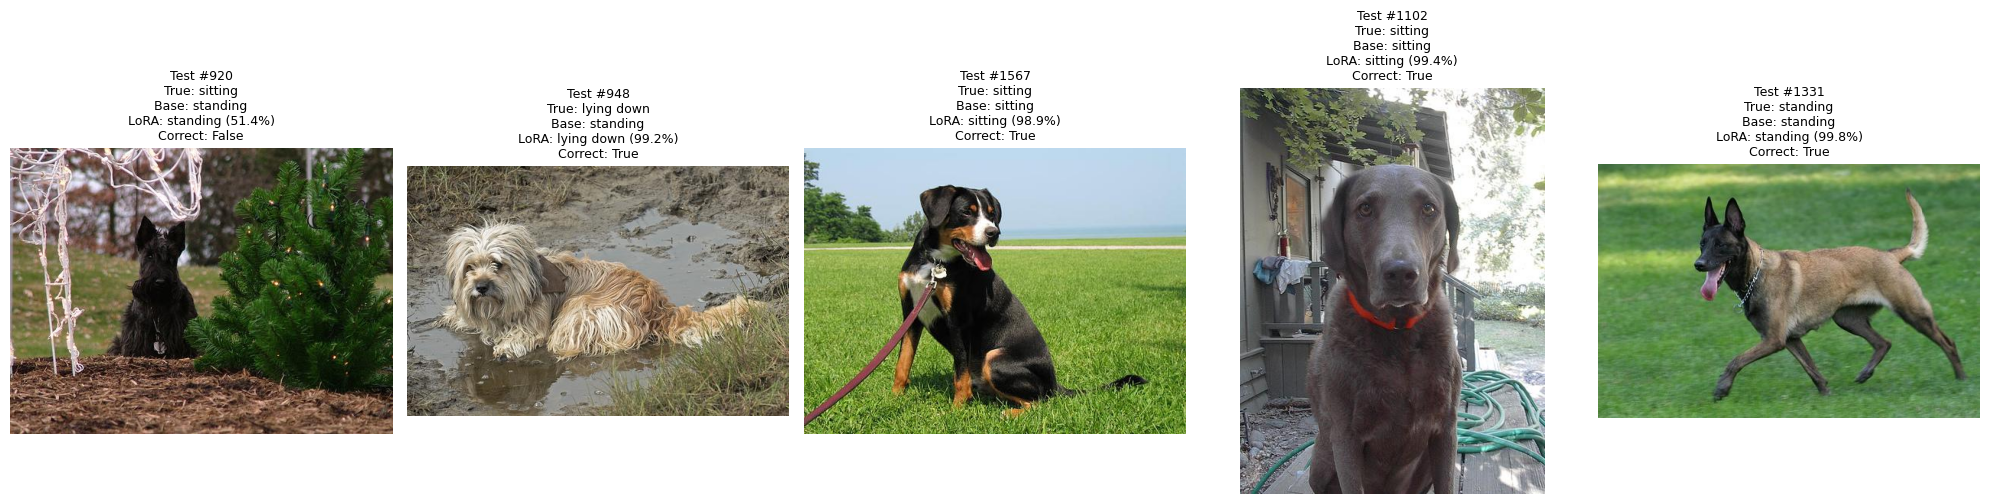

In [35]:
if evaluation_completed:
    comparison = before.rename(columns={"prediction": "baseline", "confidence": "baseline_confidence"}).merge(
        after[["sample_id", "prediction", "confidence"]].rename(columns={"prediction": "lora", "confidence": "lora_confidence"}),
        on="sample_id", validate="one_to_one")
    assert len(comparison) >= 5
    comparison["lora_correct"] = comparison.target.eq(comparison.lora)
    comparison.to_csv(OUTPUT_DIR / "predictions" / "test_comparison.csv", index=False)
    chosen = []
    for correct in [False, True]:
        subset = comparison.loc[comparison.lora_correct.eq(correct)]
        if len(subset): chosen.append(int(subset.sample(1, random_state=SEED).index[0]))
    remaining = comparison.drop(index=chosen).sample(n=5-len(chosen), random_state=SEED).index.tolist()
    examples = comparison.loc[chosen+remaining]
    display(examples.assign(target_label=examples.target.map(id2label), baseline_label=examples.baseline.map(id2label),
                            lora_label=examples.lora.map(id2label)))
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))
    for ax, row in zip(axes, examples.itertuples()):
        ax.imshow(open_rgb(EXTRACT_DIR / row.image_path)); ax.axis("off")
        ax.set_title(f"Test #{row.sample_id}\nTrue: {id2label[row.target]}\nBase: {id2label[row.baseline]}\n"
                     f"LoRA: {id2label[row.lora]} ({row.lora_confidence:.1%})\nCorrect: {row.lora_correct}", fontsize=9)
    plt.tight_layout(); fig.savefig(OUTPUT_DIR / "predictions" / "five_test_examples.png", dpi=150); plt.show()
else:
    print("최소 5개 Test 예측 비교: 미실행. GPU 학습 완료 후 이 셀에서 실제 예측을 생성한다.")

## 12. Adapter·classifier 저장 확인과 새 모델 복원

학습한 LoRA adapter와 classifier만 저장한다. Baseline은 classifier만 저장하며 backbone은 Hub 캐시에서 재사용한다.
동일 revision의 새 pretrained 모델에 adapter를 복원하고 기존 모델과 한 Test 이미지의 logits를 비교한다.
이 복원 확인은 새 Test 성능 평가가 아니며 하이퍼파라미터를 변경하지 않는다.
사용자 입력 이미지도 EXIF/RGB/processor를 동일하게 적용한다. 학습 전에는 임의의 자세 결과를 표시하지 않는다.

In [36]:
adapter_restored = False
def predict_one(current_model, processor, image_path):
    image = open_rgb(image_path)
    inputs = processor(images=image, return_tensors="pt")
    device = next(current_model.parameters()).device
    current_model.eval()
    with torch.inference_mode():
        logits = current_model(**{k: v.to(device) for k,v in inputs.items()}).logits
        scores = torch.softmax(logits.float(), dim=-1)[0]
    predicted = int(scores.argmax())
    return {"label": id2label[predicted], "confidence": float(scores[predicted]),
            "all_scores": {id2label[i]: float(v) for i,v in enumerate(scores)}}

if training_completed:
    saved = load_file(str(adapter_dir / "adapter_model.safetensors"))
    assert any("classifier" in k for k in saved), "저장된 adapter에 classifier 누락"
    assert any("lora_A" in k for k in saved) and any("lora_B" in k for k in saved)
    print("Adapter 파일 내 classifier/LoRA 확인:", len(saved), "tensors")
    restored_base, restored_processor = load_model_and_processor()
    restored_model = PeftModel.from_pretrained(restored_base, adapter_dir, is_trainable=False)
    restored_model.eval(); lora_model.eval()
    test_path = EXTRACT_DIR / raw["test"][0]["image_path"]
    pixels = restored_processor(images=open_rgb(test_path), return_tensors="pt")["pixel_values"]
    with torch.inference_mode():
        expected_logits = lora_model.to("cpu")(pixel_values=pixels).logits
        restored_logits = restored_model(pixel_values=pixels).logits
    torch.testing.assert_close(restored_logits, expected_logits, atol=1e-5, rtol=1e-4)
    adapter_restored = True
    print("새 pretrained 모델 + adapter 복원 logits 일치: 통과")
    print("Test 단일 이미지:", test_path, predict_one(restored_model, restored_processor, test_path))
    if USER_IMAGE_PATH:
        print("사용자 이미지:", predict_one(restored_model, restored_processor, Path(USER_IMAGE_PATH)))
    else:
        print("사용자 이미지 추론: USER_IMAGE_PATH 지정 후 이 셀 재실행")
else:
    print("학습된 adapter 저장/복원 및 단일 이미지 자세 추론: 미실행")

Adapter 파일 내 classifier/LoRA 확인: 50 tensors


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


새 pretrained 모델 + adapter 복원 logits 일치: 통과
Test 단일 이미지: /content/data/processed/images/n02085620-Chihuahua/n02085620_1235.jpg {'label': 'sitting', 'confidence': 0.914956271648407, 'all_scores': {'standing': 0.08133777976036072, 'sitting': 0.914956271648407, 'lying down': 0.003706037299707532}}
사용자 이미지 추론: USER_IMAGE_PATH 지정 후 이 셀 재실행


## 13. 결과 분석과 해석의 범위

Accuracy는 각 사진에 같은 비중을 주고, Macro-F1은 각 클래스의 F1에 같은 비중을 준다.
따라서 많은 `lying down` 사진을 잘 맞히면서 적은 `sitting`을 놓치면 Accuracy보다 Macro-F1이 낮아질 수 있다.
Weighted-F1은 클래스별 Test 수량으로 가중한다. 클래스별 Precision은 예측의 정확성, Recall은 실제 자세의 검출률을 나타낸다.

Train-only class weighting은 손실에서 소수 클래스의 비중을 높이지만 모든 클래스 성능의 개선을 보장하지 않는다.
Baseline도 head를 학습했으므로 LoRA 비교는 무작위 head 대비 성능 향상과 구분된다.
두 모델에 같은 학습률을 사용한 단일 seed 비교이며 최적화된 모든 대안 대비 우월성을 입증하지 않는다.

In [37]:
if evaluation_completed:
    deltas = {k: 100*(after_metrics[k]-before_metrics[k]) for k in before_metrics}
    cm = np.asarray(matrices["lora"])
    off = cm.copy(); np.fill_diagonal(off, 0)
    a,b = np.unravel_index(int(off.argmax()), off.shape)
    text = (f"동일 Test {len(raw['test'])}장: Accuracy {before_metrics['accuracy']:.2%} → {after_metrics['accuracy']:.2%}, "
            f"Macro-F1 {before_metrics['macro_f1']:.4f} → {after_metrics['macro_f1']:.4f}, "
            f"Weighted-F1 {before_metrics['weighted_f1']:.4f} → {after_metrics['weighted_f1']:.4f}. "
            f"변화량(%p)은 {deltas}. ")
    if off.max(): text += f"LoRA에서 가장 빈번한 방향성 혼동은 실제 {LABELS[a]} → 예측 {LABELS[b]} ({off[a,b]}건)이다. "
    else: text += "이 Test에서 오분류는 관찰되지 않았다. "
    text += "관찰된 혼동을 배경·가림·촬영 각도의 인과 효과라고 단정하지 않는다. Test 점수로 설정을 수정하지 않았다."
    display(Markdown(text))
    (OUTPUT_DIR / "evaluation" / "analysis.txt").write_text(text, encoding="utf-8")
else:
    display(Markdown("**학습 결과 분석: 미실행.** 데이터 감사와 코드 검증은 실행했지만 전체 Baseline/LoRA 학습을 수행하지 않았다. "
        "Accuracy·F1·혼동 쌍·성능 향상은 측정하지 않았으므로 결론을 내리지 않는다. Colab GPU 학습 후 실제 결과에서 위 분석을 생성한다."))

동일 Test 2120장: Accuracy 64.25% → 93.87%, Macro-F1 0.6058 → 0.9281, Weighted-F1 0.6469 → 0.9388. 변화량(%p)은 {'accuracy': 29.622641509433954, 'macro_f1': 32.22649402988086, 'weighted_f1': 29.189804524019436}. LoRA에서 가장 빈번한 방향성 혼동은 실제 standing → 예측 sitting (32건)이다. 관찰된 혼동을 배경·가림·촬영 각도의 인과 효과라고 단정하지 않는다. Test 점수로 설정을 수정하지 않았다.

### 데이터 편향과 일반화 한계

`undefined`는 불명확한 자세·클로즈업 등을 포함한다. 이를 제외한 3-class 모델은 그런 입력을 거절하는 기능이 없으며
실제 적용에서는 세 자세 중 하나를 강제로 반환한다. confidence만으로 undefined를 안정적으로 검출할 수 있다고 주장하지 않는다.
사람의 단일 라벨 판단 오류, 여러 마리의 강아지, 가림, 촬영 각도, 배경, 견종별 외형 차이가 성능에 영향을 줄 수 있다.
견종은 라벨이 아니며 사진만으로 부모 품종을 추측하지 않는다.

SHA·RGB·보수적인 유사 이미지 그룹 검사는 중복 누출을 줄이지만 같은 개체의 다른 사진을 모두 식별하지 못한다.
공식 개체 ID/촬영 세션이 없으므로 새 개체·새 카메라·새 환경에서 같은 성능을 보장하지 않는다.
ImageNet 기반 사전학습과 Stanford Dogs 사이 원본 중복 가능성도 독립적인 외부 검증의 필요성을 높인다.
개선 실험은 Validation 또는 별도 개발 데이터에서 설계하고 이 Test 결과를 보고 재선택하지 않는다.

## 14. 실행 방법과 최종 제출 안내

**VS Code:** 프로젝트 `.venv/Scripts/python.exe`를 인터프리터와 노트북 커널로 선택한다.
아카이브가 루트에 있으면 그대로 발견한다. 상단 설정 셀 → Drive 마운트/파일 확인 → 아카이브 → 감사 → EDA → 확정 분할 복원 → 모델 → LoRA 점검 → 학습 → 평가 → 복원 순서로 실행한다.
`RUN_MODE='audit'`는 CPU용 점검이다. GPU 학습은 `RUN_MODE='train'`으로 설정한다.

**Colab:** 이 노트북만 업로드 → 런타임에서 GPU 선택 → 환경 셀 확인 → Drive에 두 아카이브 배치 후
설정은 기본 audit 그대로 두고 위에서부터 실행한다. Drive 마운트와 실제 파일 존재/목록 확인 셀이 포함되어 있다.
Colab 기본 데이터 폴더는 정확히 `/content/drive/MyDrive/DogPoseCV`이며 출력은 그 안의 `outputs`에 자동 보관한다.
파일이 안 보이면 한 번 재마운트하고 기대 경로·실제 파일 목록을 포함한 오류를 표시한다.
런타임 삭제 전에 **파일 → 다운로드 → .ipynb 다운로드**로 실행 출력이 포함된 노트북을 저장한다.
Colab에서는 정식 마운트 셀을 실행한다. 로컬에서는 마운트하지 않는다. Colab 실제 학습 여부는 출력으로 확인해야 한다.

**최종 제출 파일:** `dog_pose_lora.ipynb` 한 개. 데이터·CSV·adapter는 재현을 위한 로컬 산출물이며 별도 제출하지 않는다.
이 로컬 실행에서 학습이 미실행이면 아직 수업의 성능 비교·5개 예측 제출 요건을 충족하지 않은 상태다.
GPU에서 전체 실행 후 결과가 포함된 노트북을 제출한다. 이미지를 별도 ZIP으로 재배포하지 않는다.

### 참고 문헌

- DogPoseCV: https://huggingface.co/datasets/stockeh/dog-pose-cv
- Stock, Jason and Tom Cavey. *Who's a Good Boy? Reinforcing Canine Behavior in Real-Time using Machine Learning.* arXiv:2101.02380. https://arxiv.org/abs/2101.02380
- ViT model card: https://huggingface.co/google/vit-base-patch16-224-in21k
- PEFT 이미지 분류 LoRA: https://huggingface.co/docs/peft/task_guides/image_classification_lora
- Transformers Trainer: https://huggingface.co/docs/transformers/v4.57.3/en/main_classes/trainer

In [38]:
execution_status = {"run_id": RUN_ID, "run_mode": RUN_MODE, "device": DEVICE,
    "data_audit_completed": True, "data_quality_ready": data_quality_ready,
    "held_images": audit.get("held_images", 0), "gate_blockers": audit.get("gate_blockers", []),
    "unlabeled_policy": UNLABELED_POLICY, "parsed_images": len(manifest), "splits": audit["split_totals"],
    "model_load_completed": model_ready, "model_error": model_error,
    "model_check_reexecuted": globals().get("model_check_reexecuted", True),
    "model_check_source_run_id": globals().get("model_check_source_run_id", RUN_ID),
    "mapping_review_executed_utc": audit.get("mapping_review_executed_utc"),
    "training_completed": training_completed, "evaluation_completed": evaluation_completed,
    "baseline_metrics": before_metrics if evaluation_completed else "미실행",
    "lora_metrics": after_metrics if evaluation_completed else "미실행",
    "adapter_saved": training_completed, "adapter_restored": adapter_restored,
    "colab_executed": IN_COLAB, "colab_training_completed": IN_COLAB and training_completed,
    "submission_ready": training_completed and evaluation_completed and adapter_restored,
    "submission_file": "dog_pose_lora.ipynb"}
write_json(OUTPUT_DIR / "evaluation" / "execution_status.json", execution_status)
print(json.dumps(execution_status, ensure_ascii=False, indent=2))

{
  "run_id": "20261126T035657_418945Z",
  "run_mode": "train",
  "device": "cuda",
  "data_audit_completed": true,
  "data_quality_ready": true,
  "held_images": 157,
  "gate_blockers": [],
  "unlabeled_policy": "exclude_unverified",
  "parsed_images": 20730,
  "splits": {
    "train": 9912,
    "validation": 2129,
    "test": 2120
  },
  "model_load_completed": true,
  "model_error": null,
  "model_check_reexecuted": true,
  "model_check_source_run_id": "20261126T035657_418945Z",
  "mapping_review_executed_utc": "2026-11-26T03:56:31.234252+00:00",
  "training_completed": true,
  "evaluation_completed": true,
  "baseline_metrics": {
    "accuracy": 0.6424528301886793,
    "macro_f1": 0.6058472747307292,
    "weighted_f1": 0.6468541327605443
  },
  "lora_metrics": {
    "accuracy": 0.9386792452830188,
    "macro_f1": 0.9281122150295378,
    "weighted_f1": 0.9387521780007386
  },
  "adapter_saved": true,
  "adapter_restored": true,
  "colab_executed": true,
  "colab_training_completed":